# PG Plotting

This notebook contains code for plotting the results of the PG algorithm. THe first part dels with plotting the results of synthetic data, while the second part focuses on plotting the results of real data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import h5py
from pathlib import Path

import os
import sys
import ast

# Add parent directory to sys.path
parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(parent_dir)

from src.models.mssv import MSSVParams

In [2]:
def generate_names(n_params):
    """
    Generate dynamically parameter names based on the number of parameters. 
    First 1 is "mu1", next K-1 are "delta_i", next one is "phi", next one is "sigma^2" and then K*K flatten parameters P_ij.
    In total there is 1 + (K-1) + 1 + 1 + K*K = K*K + K + 2 parameters.
    """
    K = int(-1+np.sqrt(n_params+1))

    names = []
    names.append("mu1")
    for i in range(K-1):
        names.append(f"delta_{i+2}")  # delta_2, delta_3, ..., delta_K
    names.append("phi")
    names.append("sigma^2")
    for i in range(K):
        for j in range(K):
            names.append(f"P_{i}_{j}")

    return names

## Synthetic Data

We plot resutls for multiple datasets, each with different regime settings. We have 6 synthetic datasets, each with 2 regimes. First three datasets have similar parameters as follows:
- $\mu_1 = -5.0$
- $\mu_2 = -2.0$
- $\sigma^2 = 0.1$
- $P = \begin{bmatrix} 0.99 & 0.01 \\ 0.015 & 0.985 \end{bmatrix}$

with different $\phi$ values:
- Dataset 1: $\phi = 0.9$
- Dataset 2: $\phi = 0.7$
- Dataset 3: $\phi = 0.5$

The next three datasets have again similar parameters as follows:
- $\mu_1 = -1.0$
- $\mu_2 = 1.0$
- $\sigma^2 = 0.05$
- $P = \begin{bmatrix} 0.99 & 0.01 \\ 0.05 & 0.95 \end{bmatrix}$

with different $\phi$ values:
- Dataset 4: $\phi = 0.9$
- Dataset 5: $\phi = 0.7$
- Dataset 6: $\phi = 0.5$




In [69]:
# Dataset name setting. Can use "dataset_1", "dataset_2", "dataset_3", "dataset_4", "dataset_5" or "dataset_6"
name = "dataset_1"

In [70]:
experiment_path = os.path.join(parent_dir, "experiments", "mssv_pg_synth")
output_dir = os.path.join(experiment_path, name, "output")
results_dir = os.path.join(experiment_path, name, "results")
# Make sure the directories exist
os.makedirs(results_dir, exist_ok=True)
data_dir = os.path.join(parent_dir, "data", "synthetic")

# Convert to pathlib.Path objects for easier path manipulation
output_dir = Path(output_dir)
results_dir = Path(results_dir)
data_dir = Path(data_dir)

In [71]:
# Load true data and parameters
data = pd.read_csv(data_dir / f"{name}.csv")
y = data["y"].values
h_true = data["h_true"].values
s_true = data["s_true"].values.astype(int)

params_df = pd.read_csv(data_dir / f"{name}_params.csv")
P_rows = params_df["P"].apply(ast.literal_eval).tolist()
P = np.array(P_rows)
true_theta = MSSVParams.from_mu(
    mu=params_df["mu"].values,
    phi=params_df["phi"].iloc[0],
    eta2=params_df["eta2"].iloc[0],
    P=P
)
true_theta = true_theta.to_vector()

In [72]:
# Get number of chain files from output_dir
chain_files = list(output_dir.glob("chain_*.h5"))
n_chains = len(chain_files)
print(f"Found {n_chains} chain files.")

# Dictionary to store chain data
chains_data = {}

for i in range(n_chains):
    print(f"Processing chain {i+1}/{n_chains}...")
    with h5py.File(output_dir / f"chain_{i}.h5", "r") as h5f:
        initial_theta = h5f.attrs["initial_parameters"]
        thetas = h5f["thetas"][:]
        logmarliks = h5f["logmarliks"][:]
        trajectories = h5f["trajectories"][:]

        chains_data[i] = {
            "initial_theta": initial_theta,
            "thetas": thetas,
            "logmarliks": logmarliks,
            "trajectories": trajectories
        }

n_params = chains_data[0]["thetas"].shape[1]

parameter_names = generate_names(n_params)
print("Parameter names:", parameter_names)

Found 16 chain files.
Processing chain 1/16...
Processing chain 2/16...
Processing chain 3/16...
Processing chain 4/16...
Processing chain 5/16...
Processing chain 6/16...
Processing chain 7/16...
Processing chain 8/16...
Processing chain 9/16...
Processing chain 10/16...
Processing chain 11/16...
Processing chain 12/16...
Processing chain 13/16...
Processing chain 14/16...
Processing chain 15/16...
Processing chain 16/16...
Parameter names: ['mu1', 'delta_2', 'phi', 'sigma^2', 'P_0_0', 'P_0_1', 'P_1_0', 'P_1_1']


In [73]:
K = int(-1+np.sqrt(n_params+1))
values = []
for param_idx in range(n_params):
    v = []
    for i in range(n_chains):
        v.extend(chains_data[i]["thetas"][:, param_idx])
    values.append(v)

values = np.array(values)  # Convert to a NumPy array for easier manipulation
thetas = []
for t in values.T:
    theta = MSSVParams(
        mu1=t[0],
        delta=t[1:K],
        phi=t[K],
        eta2=t[K + 1],
        P=t[K + 2:].reshape((K, K))
    )
    thetas.append(theta.to_unconstrained())

thetas = np.array(thetas)
mean = np.mean(thetas, axis=0)
cov = np.cov(thetas, rowvar=False)

print("Mean of thetas:")
print(mean)
print("Covariance of thetas:")
print(cov)

Mean of thetas:
[-4.98482173  1.16743846  1.40499764 -2.48063966  4.28423732 -4.26342087]
Covariance of thetas:
[[ 0.0143865  -0.00184834 -0.00200063  0.00646166  0.00733815 -0.0023073 ]
 [-0.00184834  0.00255565  0.00133257 -0.00548844 -0.00429827  0.00448557]
 [-0.00200063  0.00133257  0.00782707 -0.01155396 -0.00262653  0.00186075]
 [ 0.00646166 -0.00548844 -0.01155396  0.05590378  0.01953146 -0.0187465 ]
 [ 0.00733815 -0.00429827 -0.00262653  0.01953146  0.11490608 -0.04176788]
 [-0.0023073   0.00448557  0.00186075 -0.0187465  -0.04176788  0.1227231 ]]


First we plot traceplots for all parameters $\mu_1, \delta_2, \phi, \sigma^2$ and $P$. The plots are saved in the `results_dir` directory.

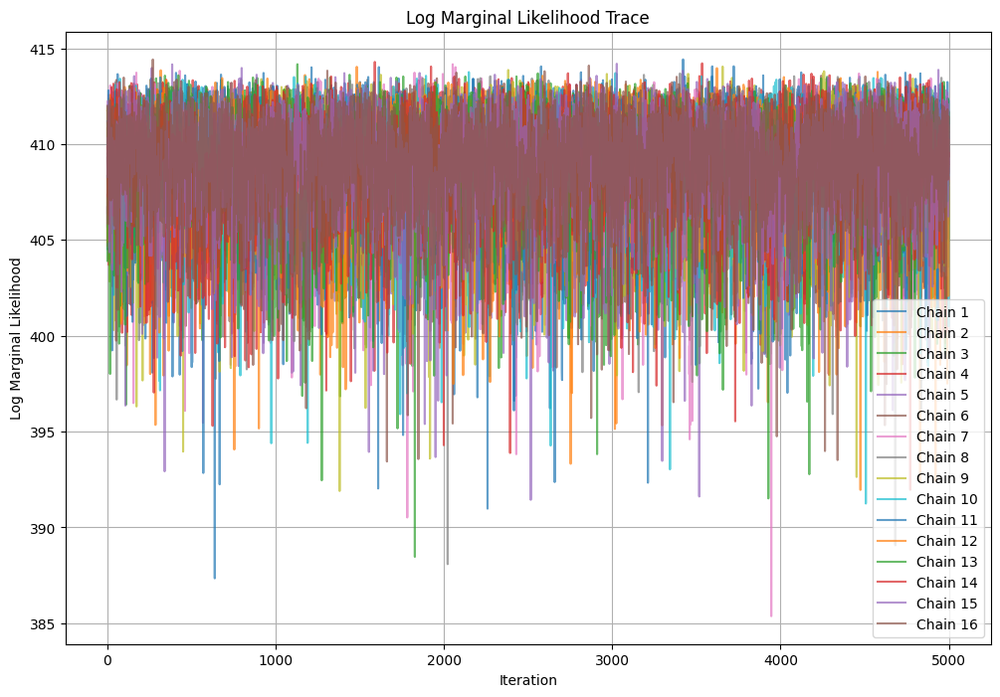

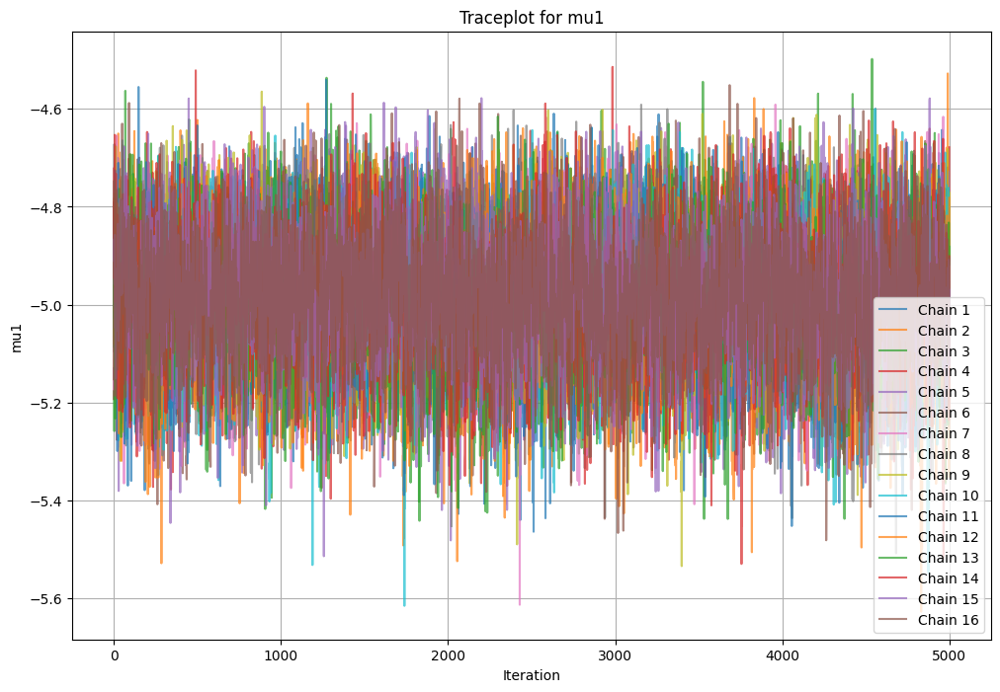

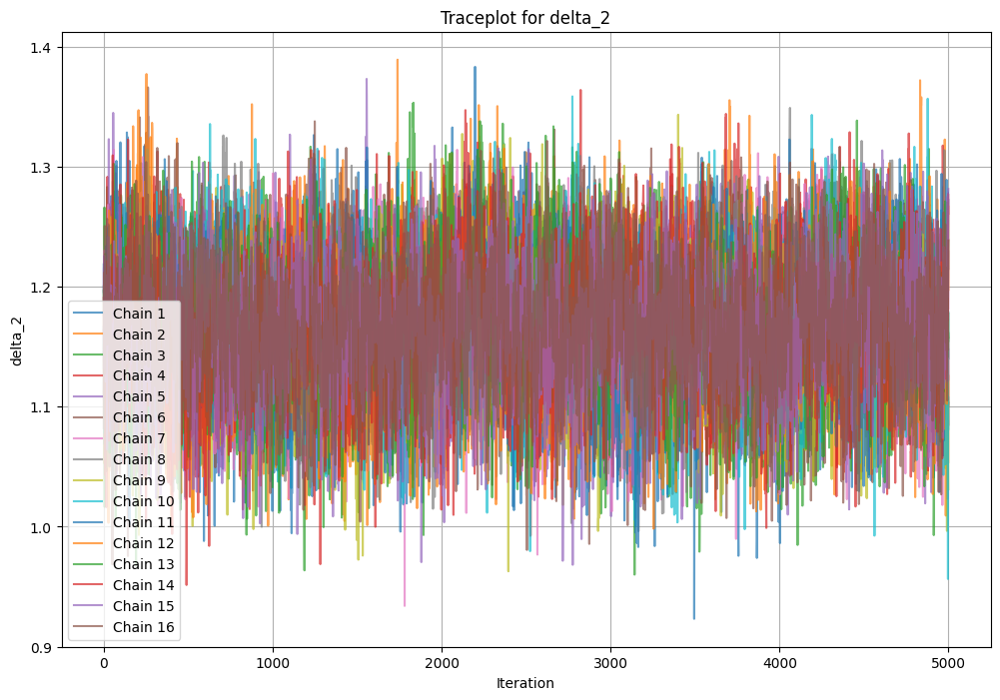

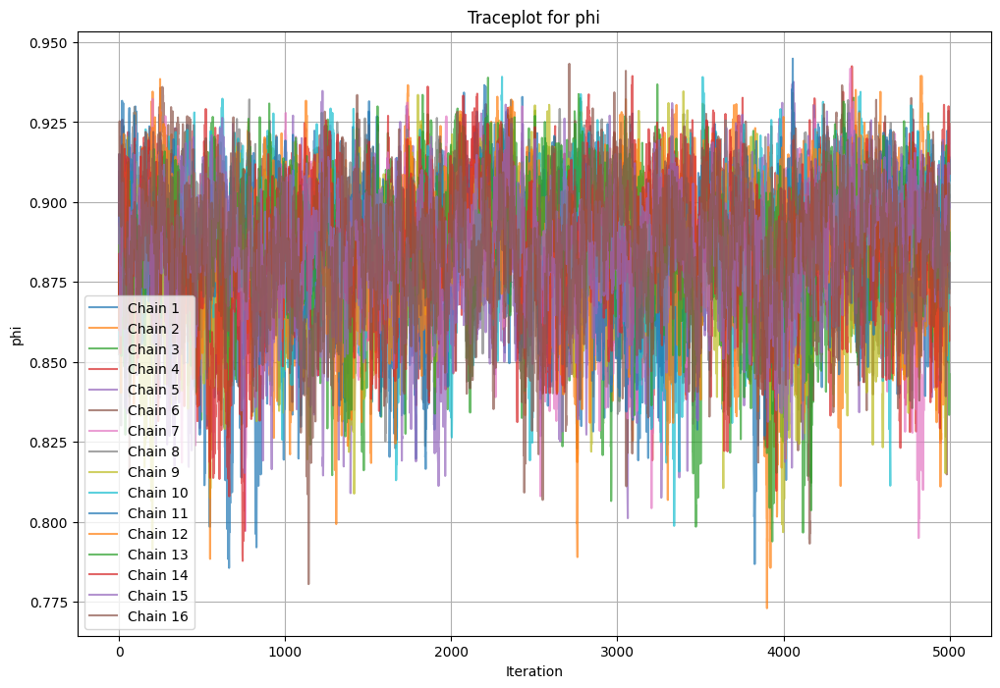

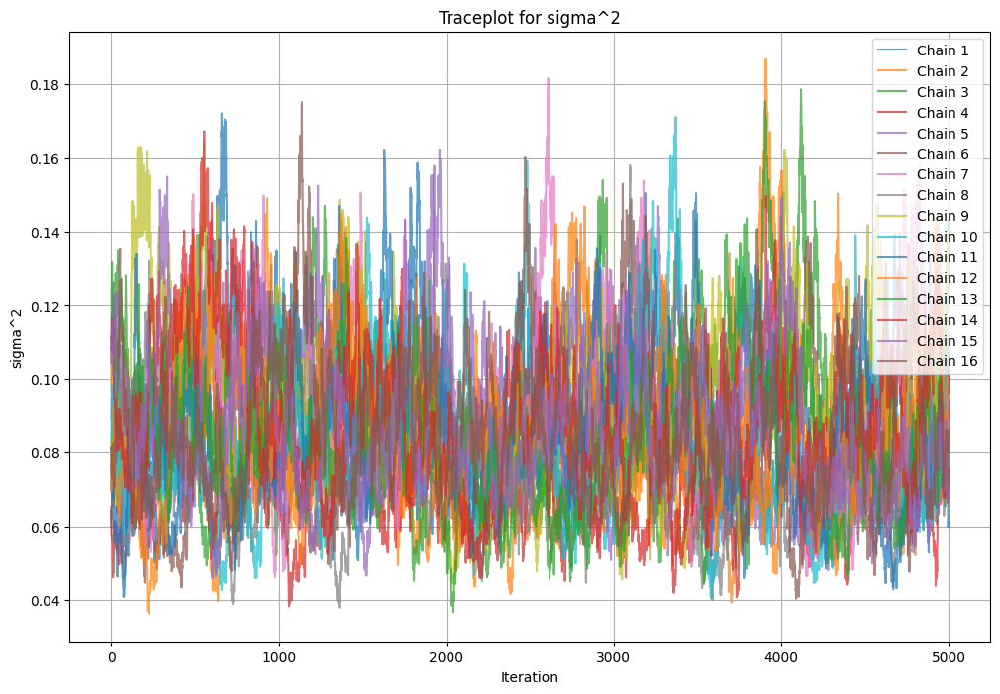

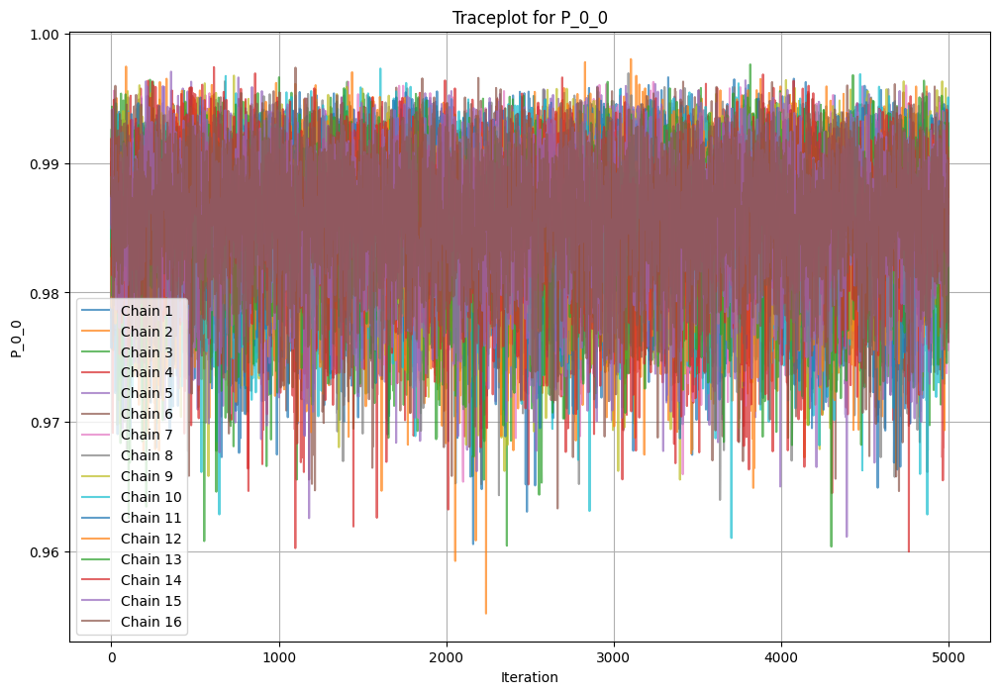

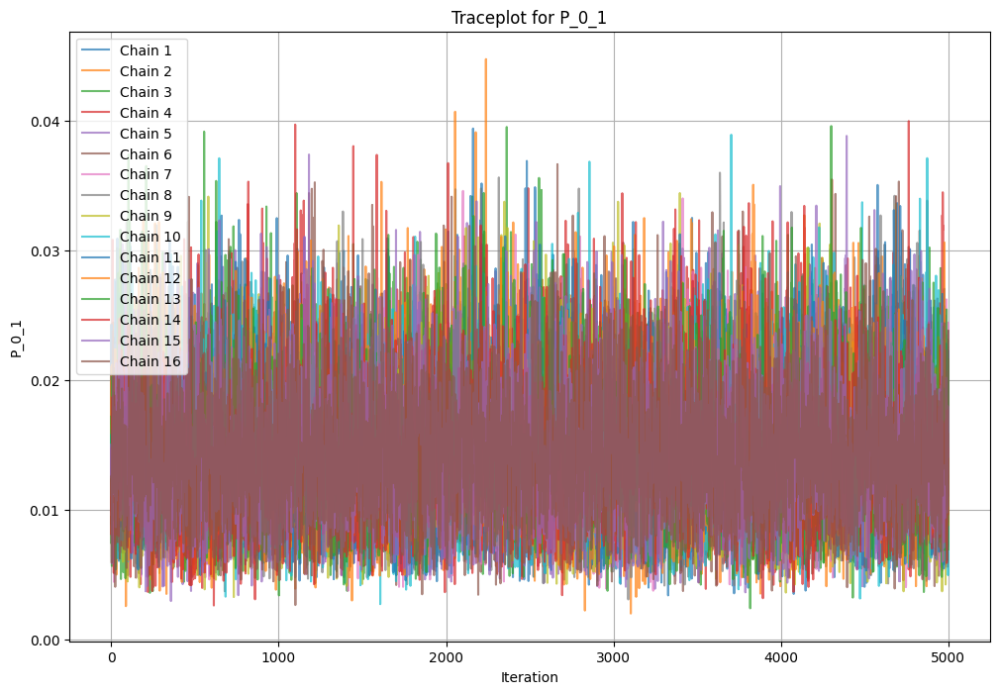

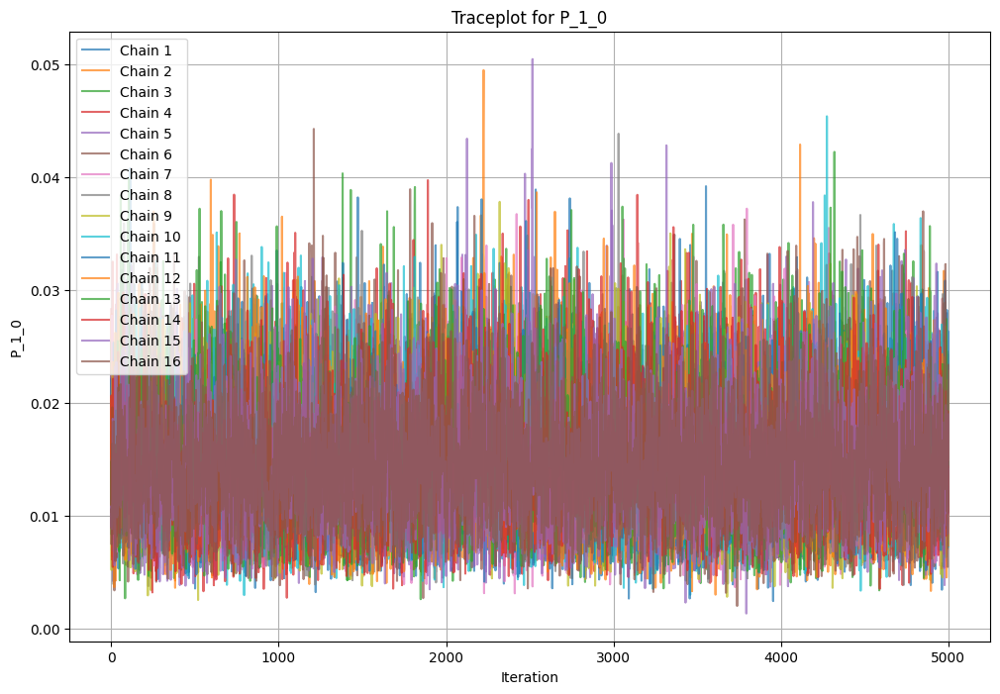

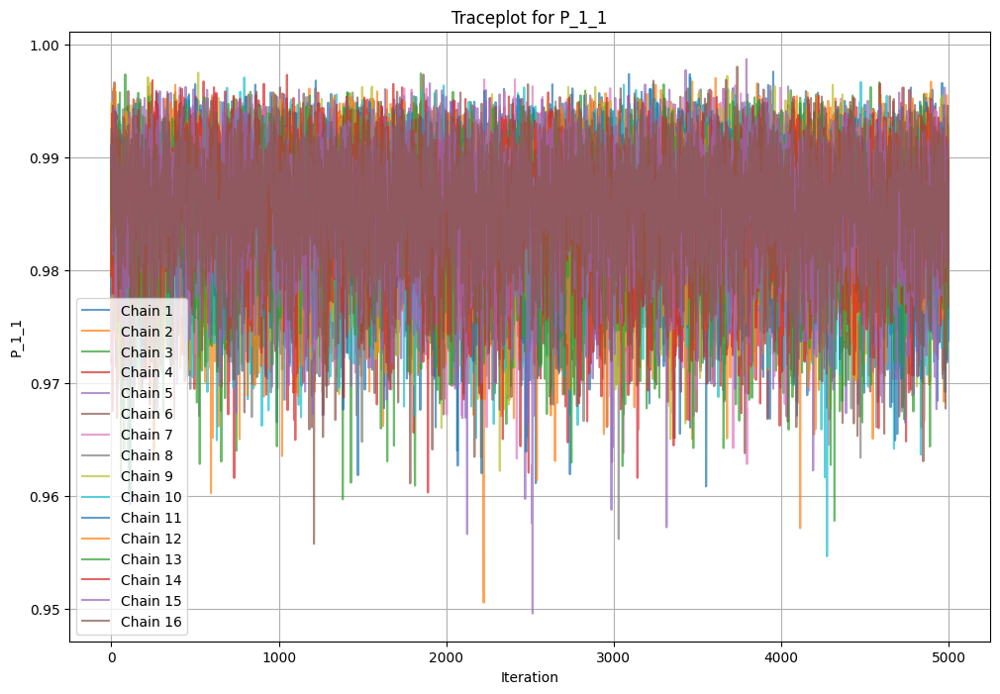

In [74]:
plt.figure(figsize=(12, 8))
for i in range(n_chains):
    plt.plot(chains_data[i]["logmarliks"], label=f"Chain {i+1}", alpha=0.7)
plt.xlabel("Iteration")
plt.ylabel("Log Marginal Likelihood")
plt.title("Log Marginal Likelihood Trace")
plt.legend()
plt.grid()
plt.savefig(results_dir / "logmarlik_trace.png")
plt.show()

for param_idx in range(n_params):
    plt.figure(figsize=(12, 8))
    for i in range(n_chains):
        plt.plot(chains_data[i]["thetas"][:, param_idx], label=f"Chain {i+1}", alpha=0.7)
    plt.xlabel("Iteration")
    plt.ylabel(parameter_names[param_idx])
    plt.title(f"Traceplot for {parameter_names[param_idx]}")
    plt.legend()
    plt.grid()
    plt.savefig(results_dir / f"{parameter_names[param_idx]}_trace.png")
    plt.show()

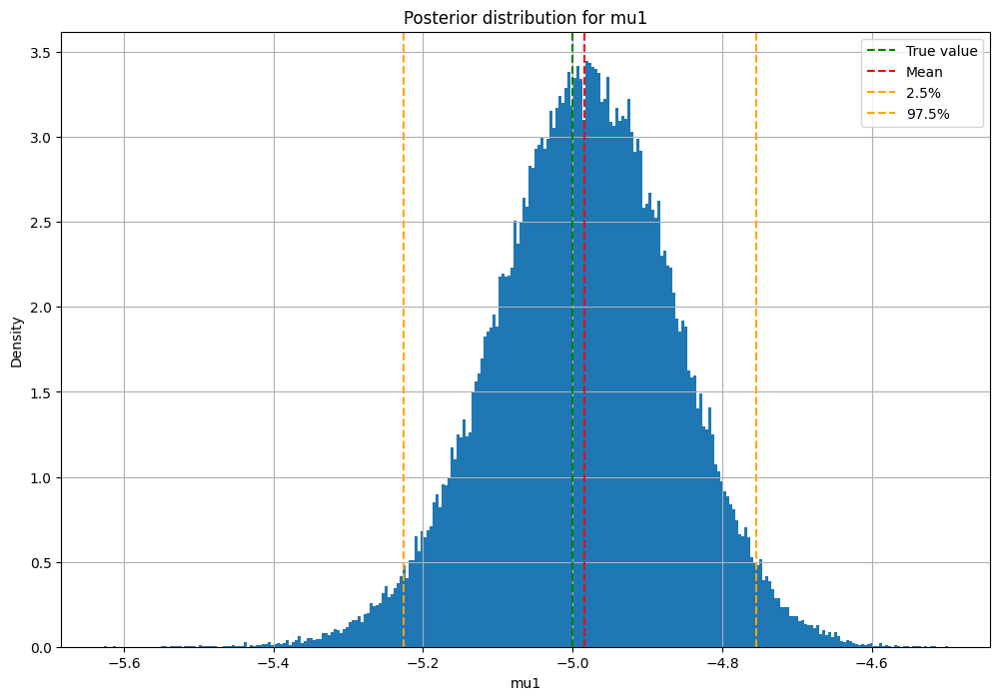

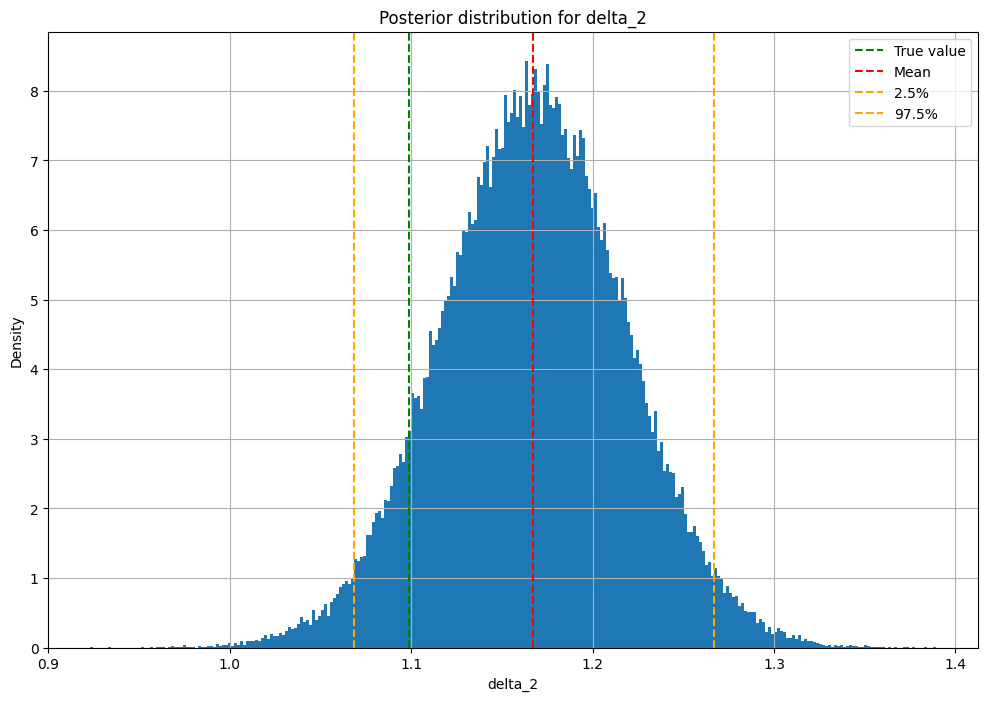

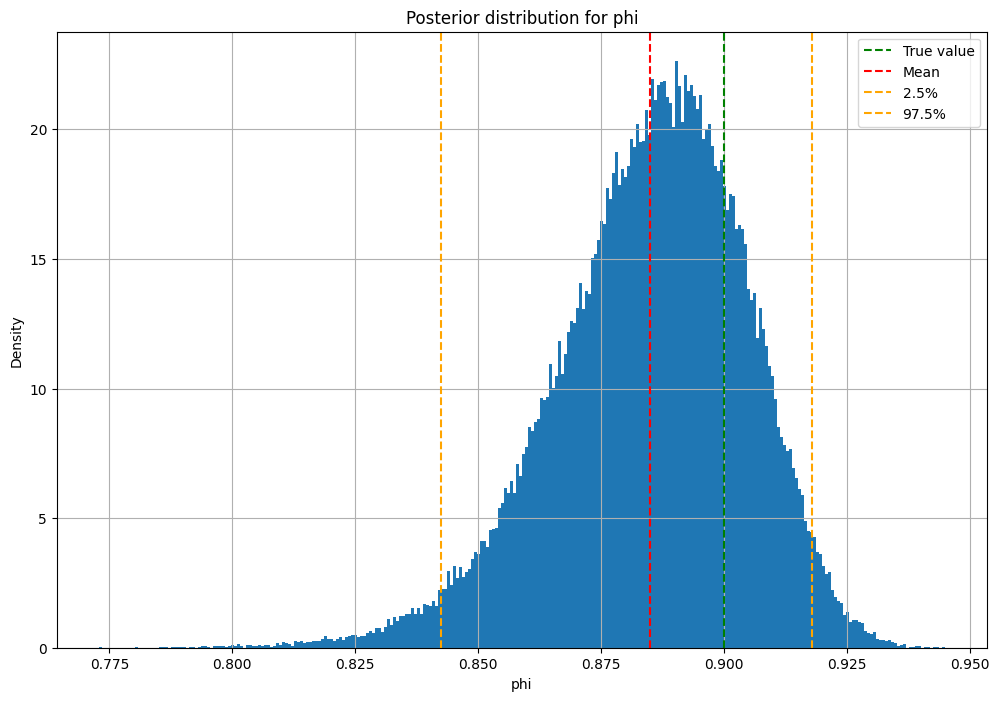

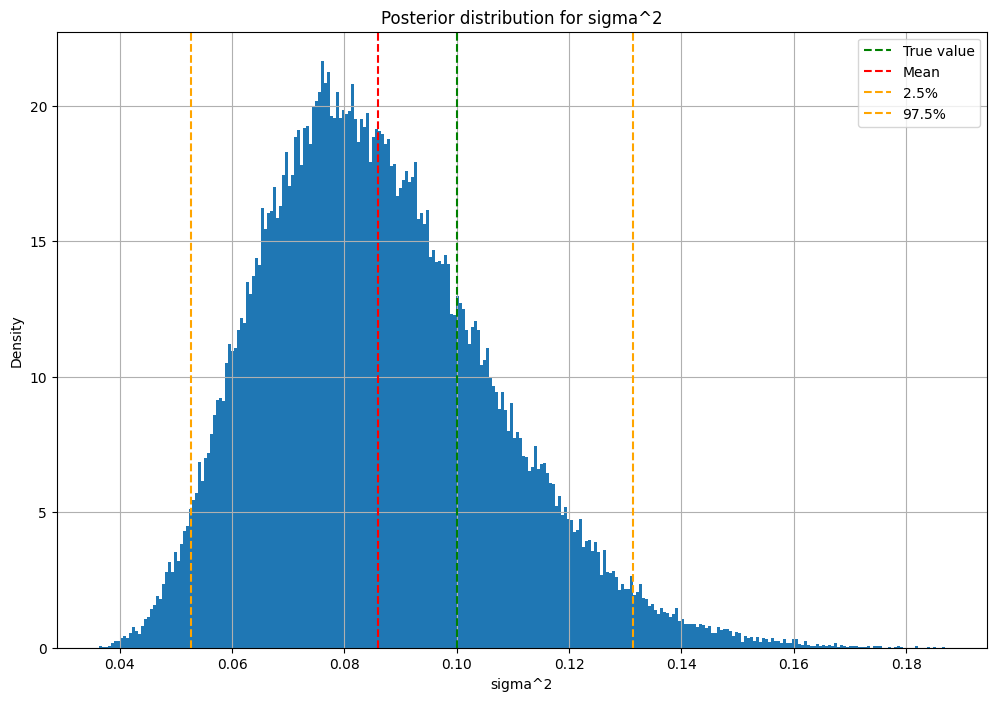

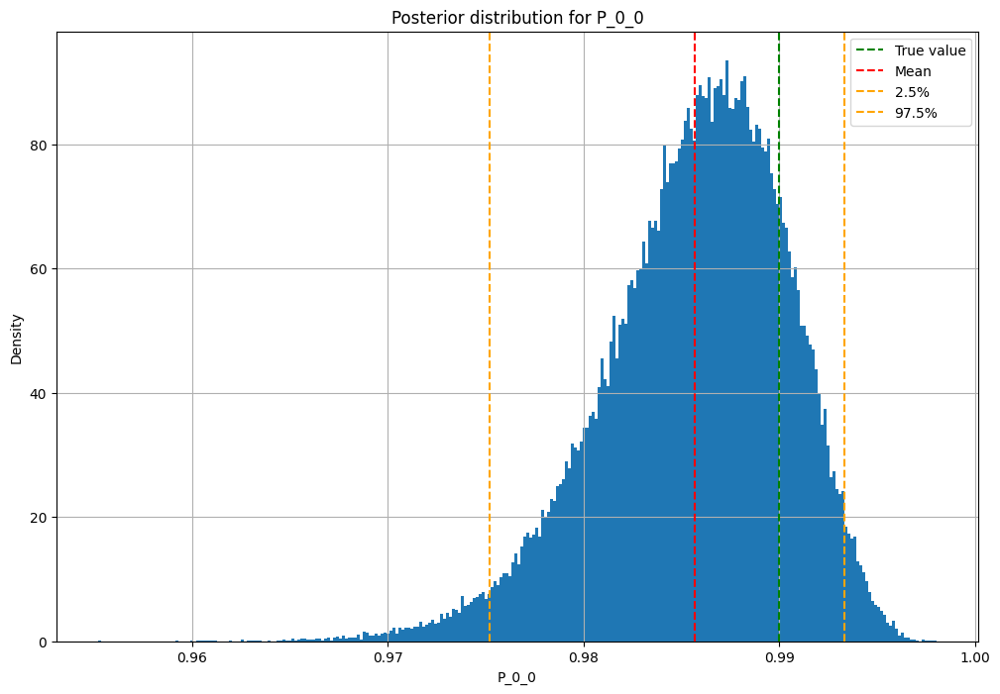

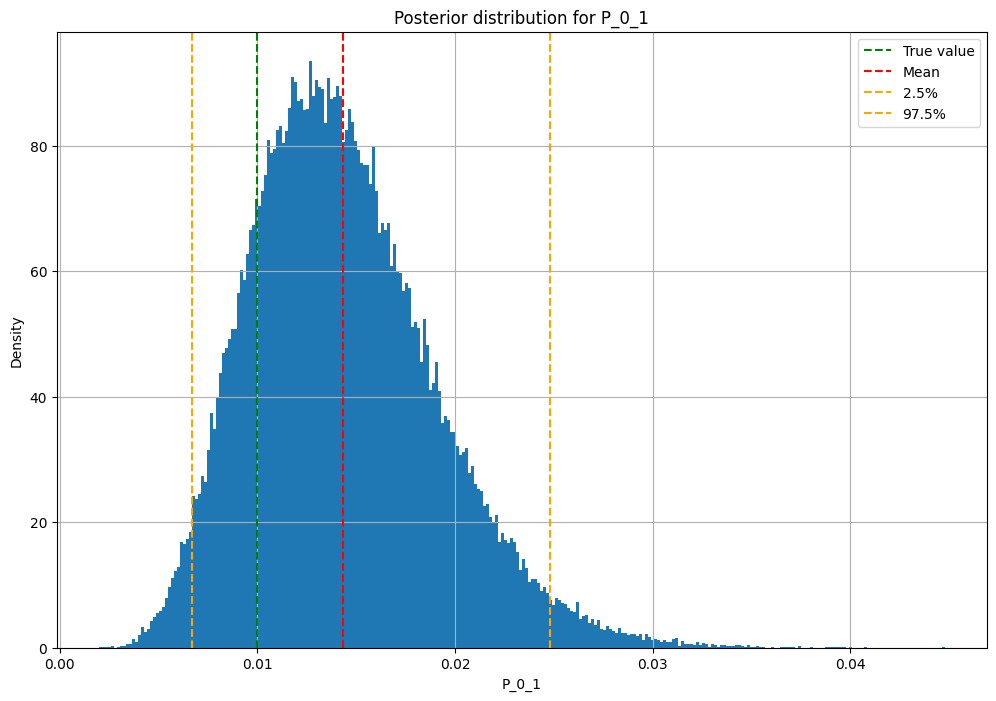

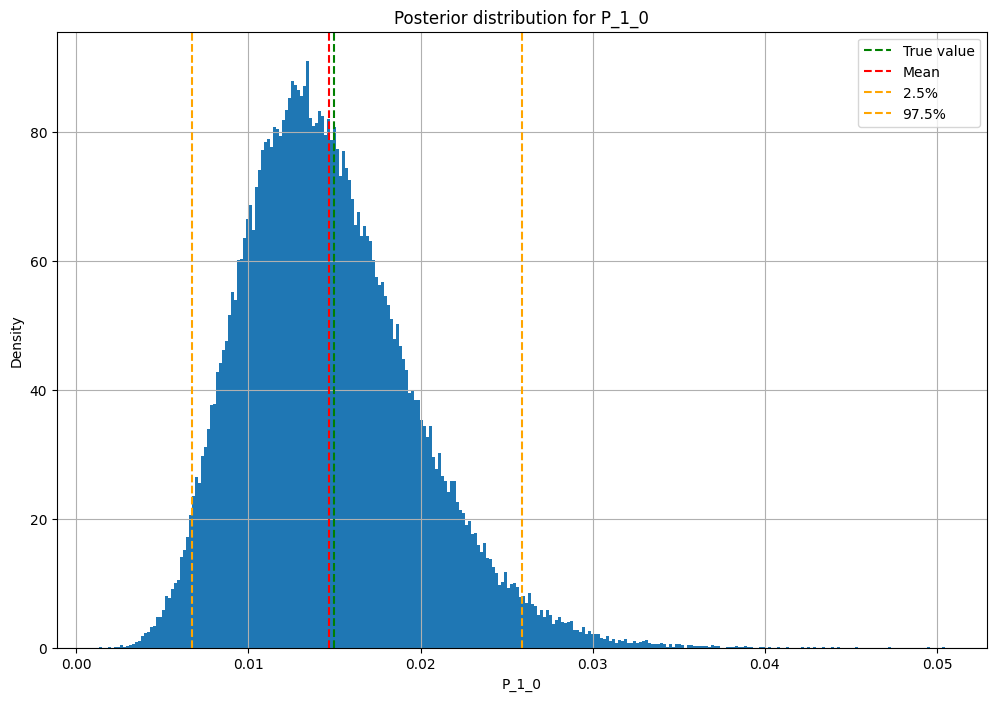

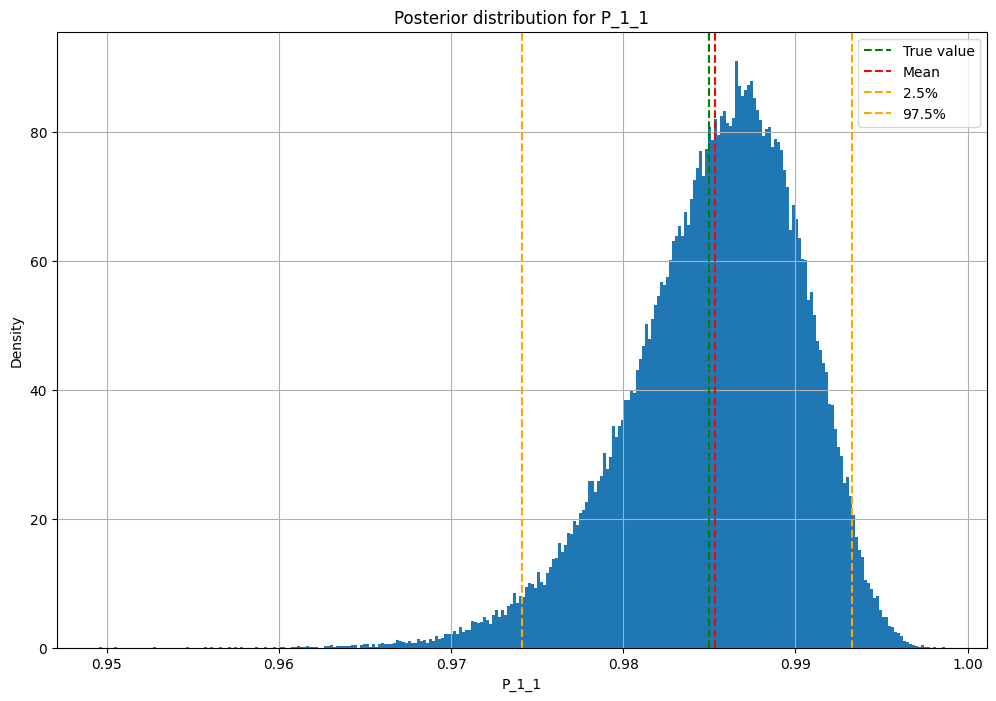

In [75]:
for param_idx in range(n_params):
    plt.figure(figsize=(12, 8))
    samples = []
    for i in range(n_chains):
        samples.extend(chains_data[i]["thetas"][:, param_idx])
    mean = np.mean(samples)
    lower, higher = np.percentile(samples, [2.5, 97.5])
    plt.hist(samples, bins=int(np.sqrt(len(samples))), density=True)
    plt.axvline(true_theta[param_idx], color='green', linestyle='--', label='True value')
    plt.axvline(mean, color='red', linestyle='--', label='Mean')
    plt.axvline(lower, color='orange', linestyle='--', label='2.5%')
    plt.axvline(higher, color='orange', linestyle='--', label='97.5%')
    plt.xlabel(parameter_names[param_idx])
    plt.ylabel("Density")
    plt.title(f"Posterior distribution for {parameter_names[param_idx]}")
    plt.grid()
    plt.legend()
    plt.savefig(results_dir / f"{parameter_names[param_idx]}_hist.png")
    plt.show()

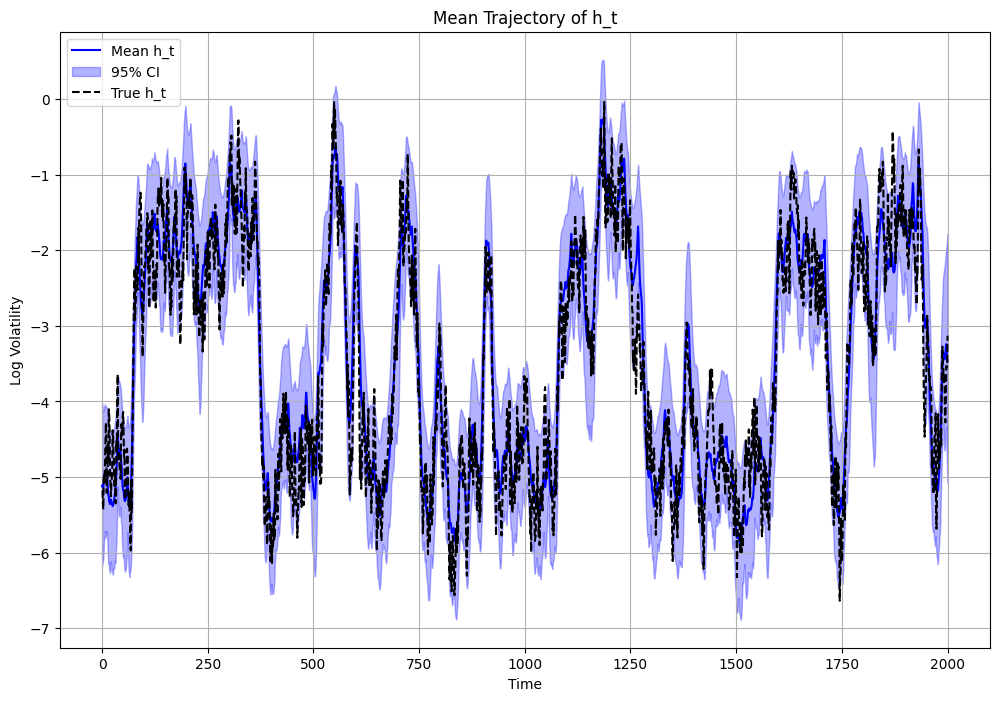

In [76]:
h_values_all_chains = []
s_values_all_chains = []
for i in range(n_chains):
    h_values = chains_data[i]["trajectories"][:, :, 0]    # shape (M, T+1)
    h_values_all_chains.append(h_values)
    # Construct back the one-hot encoded regime indicators
    s_values = chains_data[i]["trajectories"][:, :, 1:]   # shape (M, T+1, K)
    s_values_all_chains.append(s_values)

# Compute mean trajectory across all chains
h_values = np.concatenate(h_values_all_chains, axis=0)
mean_h_values = np.mean(h_values, axis=0)    # shape (T+1,)
lower, higher = np.percentile(h_values, [2.5, 97.5], axis=0)

plt.figure(figsize=(12, 8))
plt.plot(mean_h_values, label="Mean h_t", color='blue')
plt.fill_between(np.arange(len(mean_h_values)), lower, higher, color='blue', alpha=0.3, label="95% CI")
plt.plot(np.arange(1, len(h_true)+1), h_true, label="True h_t", color='black', linestyle='--')
plt.xlabel("Time")
plt.ylabel("Log Volatility")
plt.title("Mean Trajectory of h_t")
plt.legend()
plt.grid()
plt.savefig(results_dir / "mean_h_trajectory.png")
plt.show()

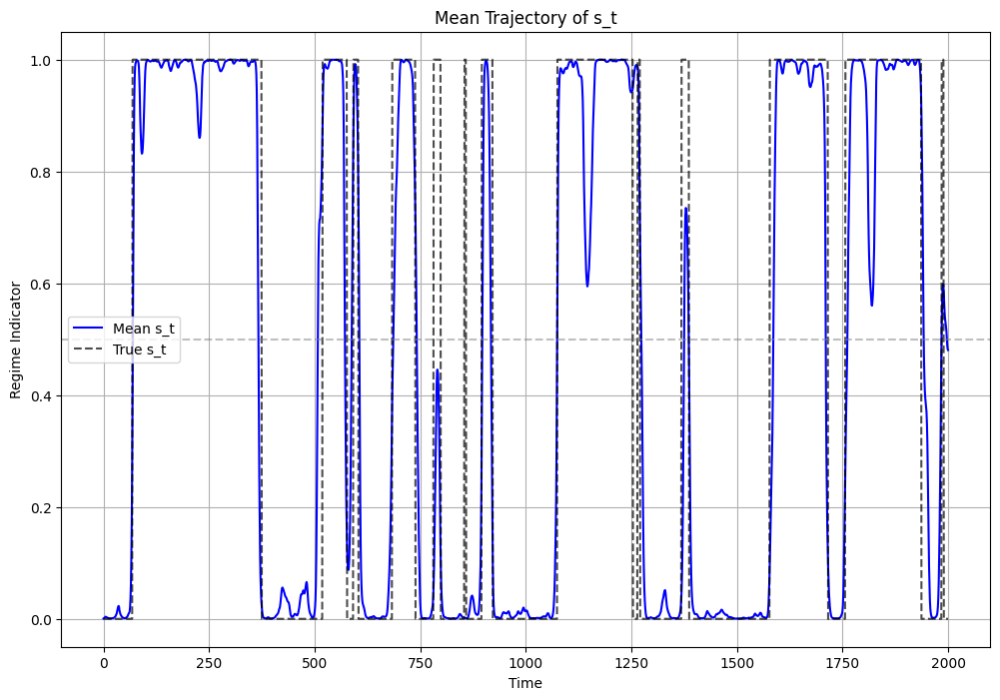

In [77]:
s_values = np.concatenate(s_values_all_chains, axis=0)
mean_s_values = np.mean(s_values, axis=0)  # shape (T+1,)
plt.figure(figsize=(12, 8))
plt.plot(mean_s_values, label="Mean s_t", color='blue')
plt.plot(np.arange(1, len(s_true)+1), s_true, label="True s_t", color='black', linestyle='--', alpha=0.7)
plt.axhline(y=0.5, color='grey', linestyle='--', alpha=0.5)
plt.xlabel("Time")
plt.ylabel("Regime Indicator")
plt.title("Mean Trajectory of s_t")
plt.legend()
plt.grid()
plt.savefig(results_dir / "mean_s_trajectory.png")
plt.show()

## Real data

Now we plot the results of the PMMH algorithm on real data. 

### S&P 500 Data
First we look at S&P 500 data, over last 26 years (since 1.1.2000). First plots are the traceplots of the parameters and the histograms of the posterior distributions. 

In [3]:
experiment_path = os.path.join(parent_dir, "experiments", "mssv_pg_sp500")
name = "sp500"

output_dir = os.path.join(experiment_path, name, "output")
results_dir = os.path.join(experiment_path, name, "results")
data_dir = os.path.join(parent_dir, "data", "real")

# Convert to pathlib.Path objects for easier path manipulation
output_dir = Path(output_dir)
results_dir = Path(results_dir)
data_dir = Path(data_dir)

In [4]:
# Get number of chain files from output_dir
chain_files = list(output_dir.glob("chain_*.h5"))
n_chains = len(chain_files)
print(f"Found {n_chains} chain files.")

# Dictionary to store chain data
chains_data = {}

for i in range(n_chains):
    print(f"Processing chain {i+1}/{n_chains}...")
    with h5py.File(output_dir / f"chain_{i}.h5", "r") as h5f:
        initial_theta = h5f.attrs["initial_parameters"]
        thetas = h5f["thetas"][:]
        logmarliks = h5f["logmarliks"][:]
        trajectories = h5f["trajectories"][:]

        chains_data[i] = {
            "initial_theta": initial_theta,
            "thetas": thetas,
            "logmarliks": logmarliks,
            "trajectories": trajectories
        }

n_params = chains_data[0]["thetas"].shape[1]
T_plus_1 = chains_data[0]["trajectories"].shape[1]

parameter_names = generate_names(n_params)
print("Parameter names:", parameter_names)
print("Number of time points (T+1):", T_plus_1)

Found 32 chain files.
Processing chain 1/32...
Processing chain 2/32...
Processing chain 3/32...
Processing chain 4/32...
Processing chain 5/32...
Processing chain 6/32...
Processing chain 7/32...
Processing chain 8/32...
Processing chain 9/32...
Processing chain 10/32...
Processing chain 11/32...
Processing chain 12/32...
Processing chain 13/32...
Processing chain 14/32...
Processing chain 15/32...
Processing chain 16/32...
Processing chain 17/32...
Processing chain 18/32...
Processing chain 19/32...
Processing chain 20/32...
Processing chain 21/32...
Processing chain 22/32...
Processing chain 23/32...
Processing chain 24/32...
Processing chain 25/32...
Processing chain 26/32...
Processing chain 27/32...
Processing chain 28/32...
Processing chain 29/32...
Processing chain 30/32...
Processing chain 31/32...
Processing chain 32/32...
Parameter names: ['mu1', 'delta_2', 'phi', 'sigma^2', 'P_0_0', 'P_0_1', 'P_1_0', 'P_1_1']
Number of time points (T+1): 6664


In [5]:
K = int(-1+np.sqrt(n_params+1))
if K >= 2:
    # Identify the indices of the diagonal elements of the transition matrix P in the parameter vector
    P_diag_indices = [2 + K + i * (K + 1) for i in range(K)]
    print("Indices of diagonal elements of P:", P_diag_indices)

Indices of diagonal elements of P: [4, 7]


In [6]:
collapsed_chains = set()  # Use a set to avoid duplicates

for param_idx in range(n_params):
    for i in range(n_chains):
        if param_idx in P_diag_indices:
            if np.all(np.isclose(chains_data[i]["thetas"][:, param_idx], 1.0)):
                collapsed_chains.add(i)
            if np.all(np.isclose(chains_data[i]["thetas"][:, param_idx], 0.0)):
                collapsed_chains.add(i)

print(f"Chains that collapsed to 1 regime dynamics: {sorted(collapsed_chains)}")
print(f"Remaining chains: {sorted(set(range(n_chains)) - collapsed_chains)}")

Chains that collapsed to 1 regime dynamics: []
Remaining chains: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]


In [7]:
values = []
for param_idx in range(n_params):
    v = []
    for i in range(n_chains):
        if i in collapsed_chains:
            continue  # Skip processing for collapsed chains
        v.extend(chains_data[i]["thetas"][:, param_idx])
    values.append(v)

values = np.array(values)  # Convert to a NumPy array for easier manipulation
thetas = []
for t in values.T:
    theta = MSSVParams(
        mu1=t[0],
        delta=t[1:K],
        phi=t[K],
        eta2=t[K + 1],
        P=t[K + 2:].reshape((K, K))
    )
    thetas.append(theta.to_unconstrained())

thetas = np.array(thetas)
mean = np.mean(thetas, axis=0)
cov = np.cov(thetas, rowvar=False)

print("Mean of thetas:")
print(mean)
print("Covariance of thetas:")
print(cov)

Mean of thetas:
[-9.93623726  0.60407813  1.86006374 -2.93342008  5.80383378 -4.70624799]
Covariance of thetas:
[[ 0.02201262  0.03819681  0.0124389  -0.01102688  0.01693137  0.07864061]
 [ 0.03819681  0.20358114  0.03782859 -0.04728986 -0.00573644  0.34214058]
 [ 0.0124389   0.03782859  0.01820695 -0.01907816 -0.00121008  0.08218487]
 [-0.01102688 -0.04728986 -0.01907816  0.03224086  0.01481829 -0.10006206]
 [ 0.01693137 -0.00573644 -0.00121008  0.01481829  0.30383978 -0.17239469]
 [ 0.07864061  0.34214058  0.08218487 -0.10006206 -0.17239469  0.88031223]]


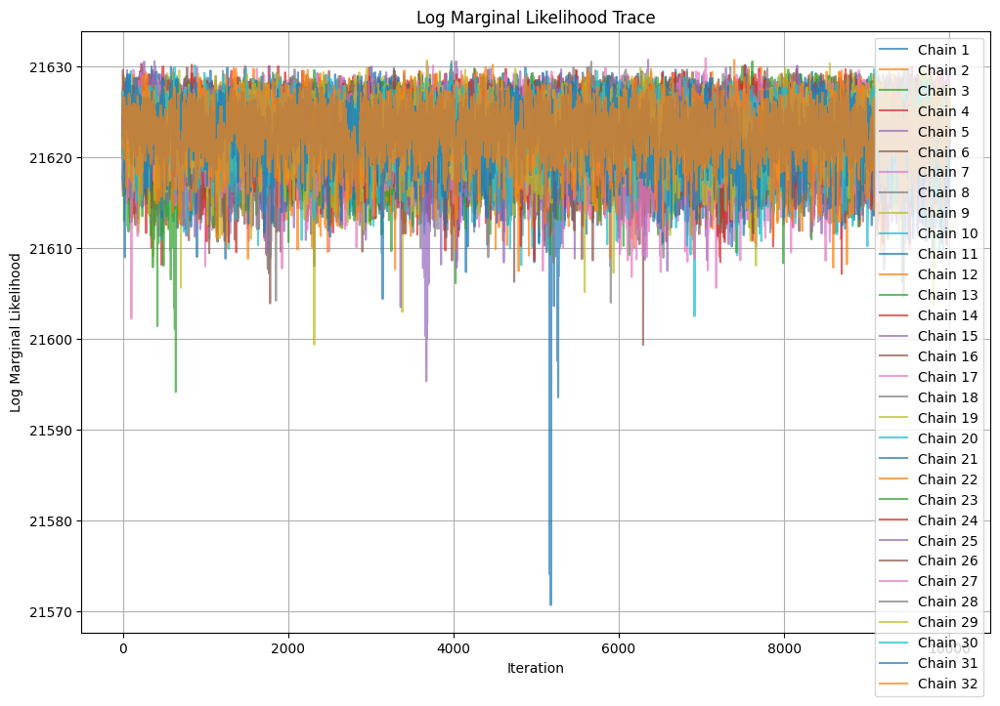

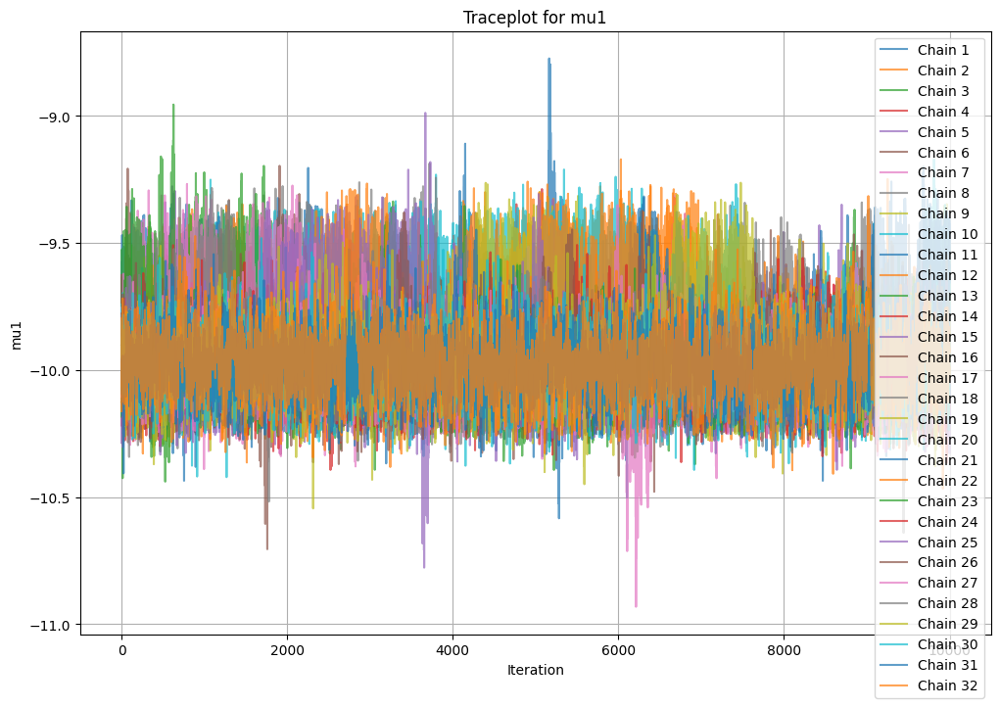

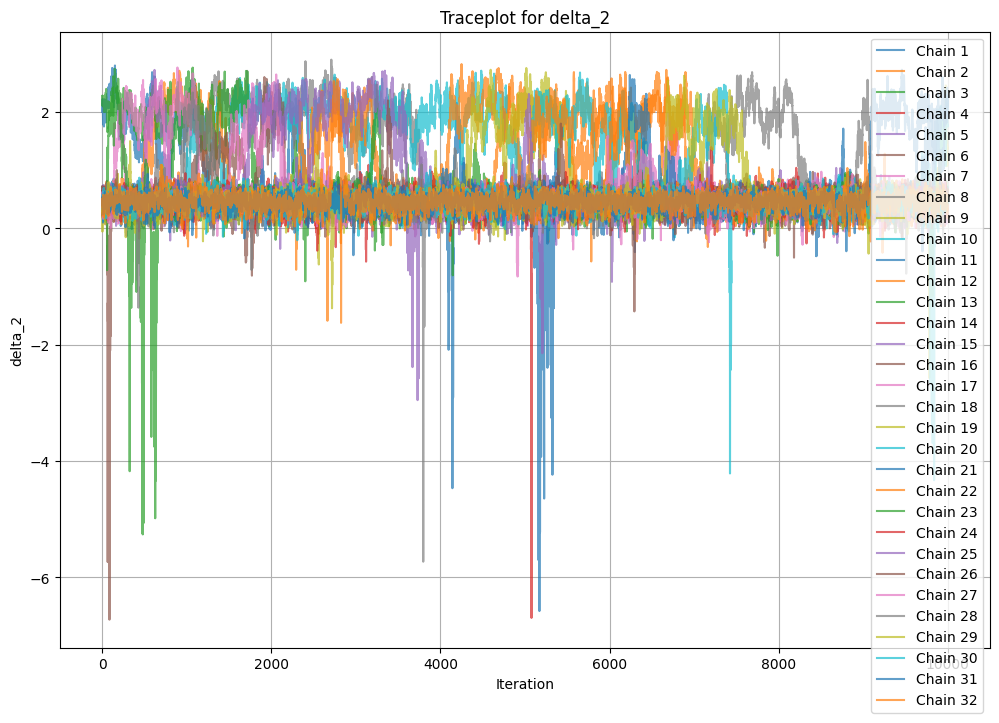

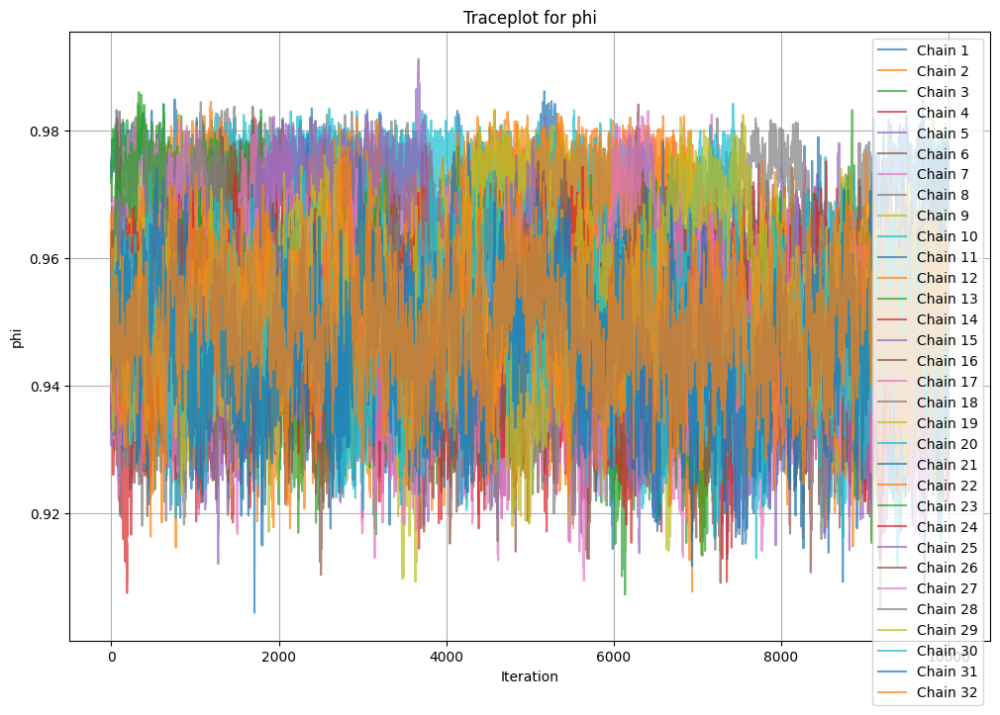

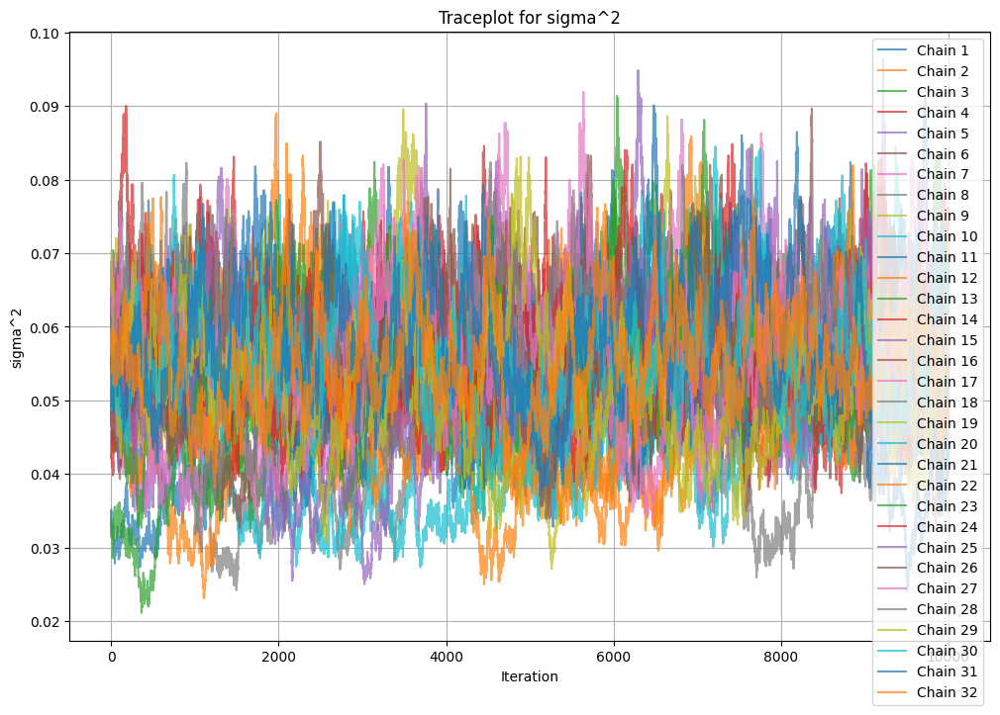

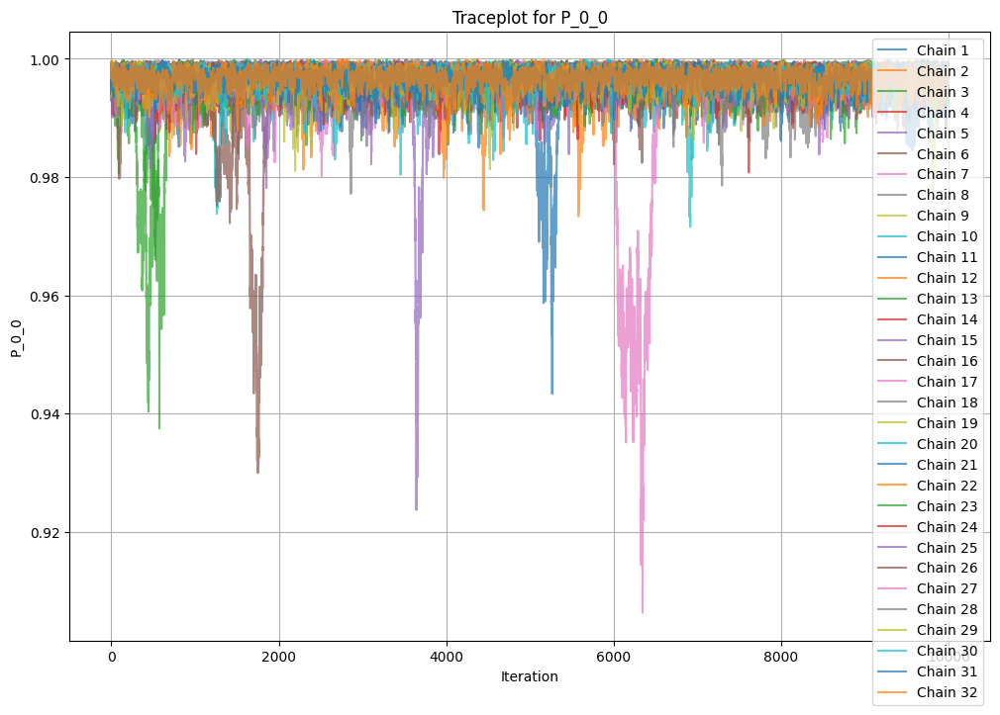

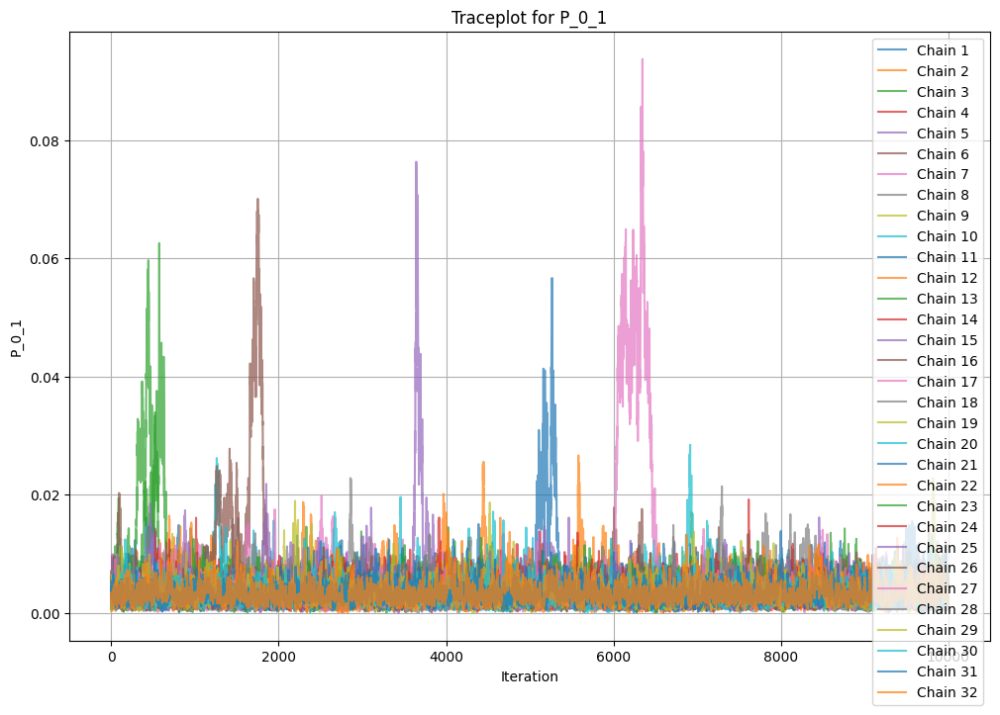

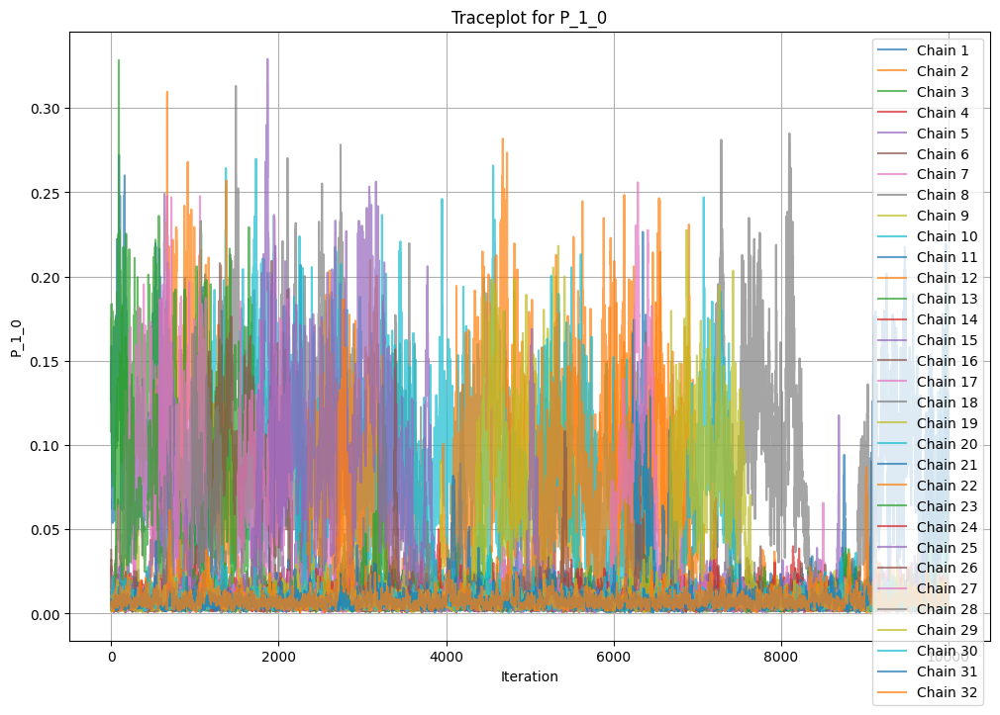

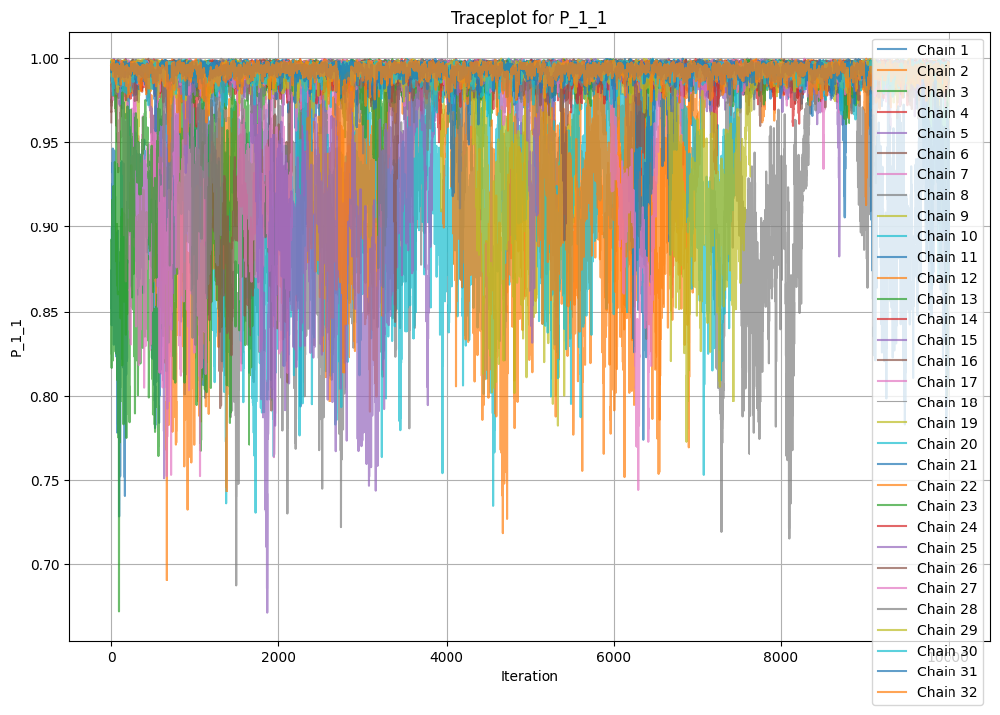

In [8]:
plt.figure(figsize=(12, 8))
for i in range(n_chains):
    if i in collapsed_chains:
        continue  # Skip plotting for collapsed chains
    plt.plot(chains_data[i]["logmarliks"], label=f"Chain {i+1}", alpha=0.7)
plt.xlabel("Iteration")
plt.ylabel("Log Marginal Likelihood")
plt.title("Log Marginal Likelihood Trace")
plt.legend()
plt.grid()
plt.savefig(results_dir / "logmarlik_trace.png")
plt.show()

for param_idx in range(n_params):
    plt.figure(figsize=(12, 8))
    for i in range(n_chains):
        if i in collapsed_chains:
            continue  # Skip plotting for collapsed chains
        plt.plot(chains_data[i]["thetas"][:, param_idx], label=f"Chain {i+1}", alpha=0.7)
    plt.xlabel("Iteration")
    plt.ylabel(parameter_names[param_idx])
    plt.title(f"Traceplot for {parameter_names[param_idx]}")
    plt.legend()
    plt.grid()
    plt.savefig(results_dir / f"{parameter_names[param_idx]}_trace.png")
    plt.show()

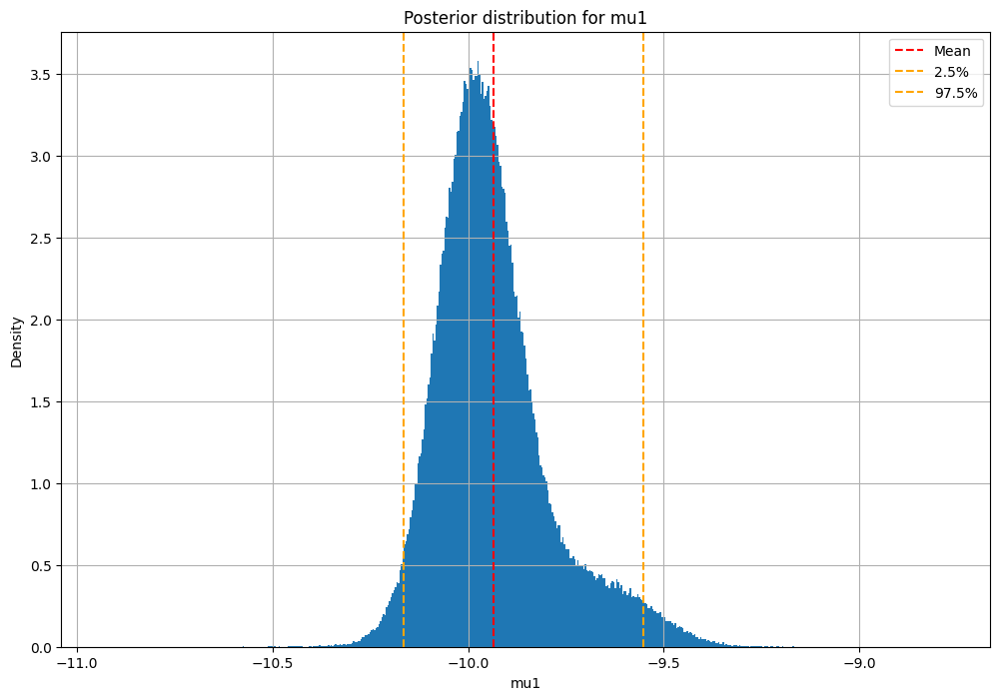

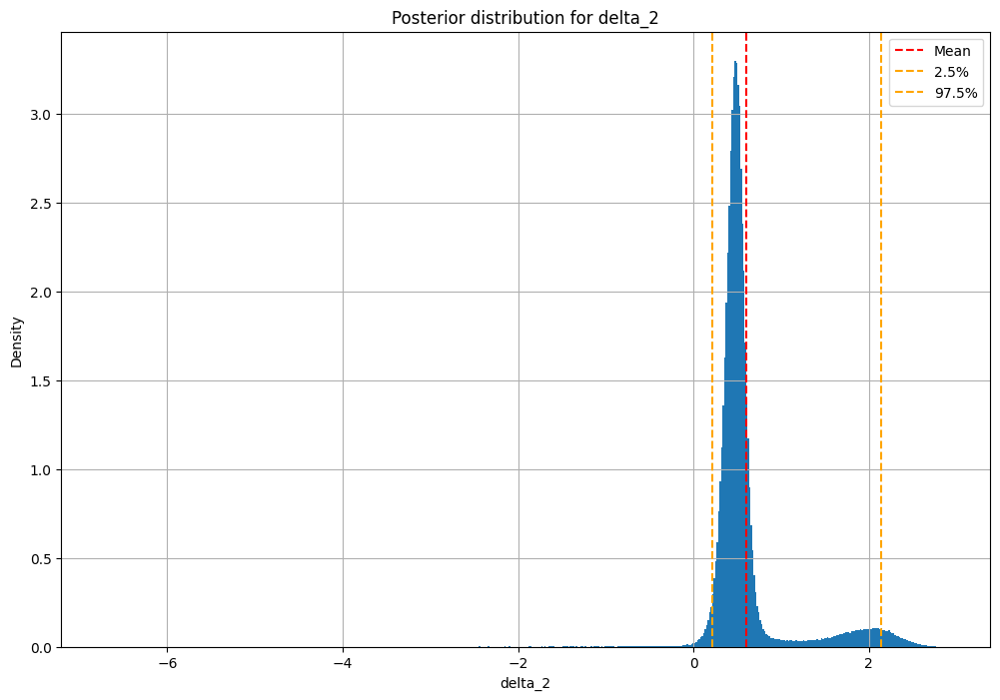

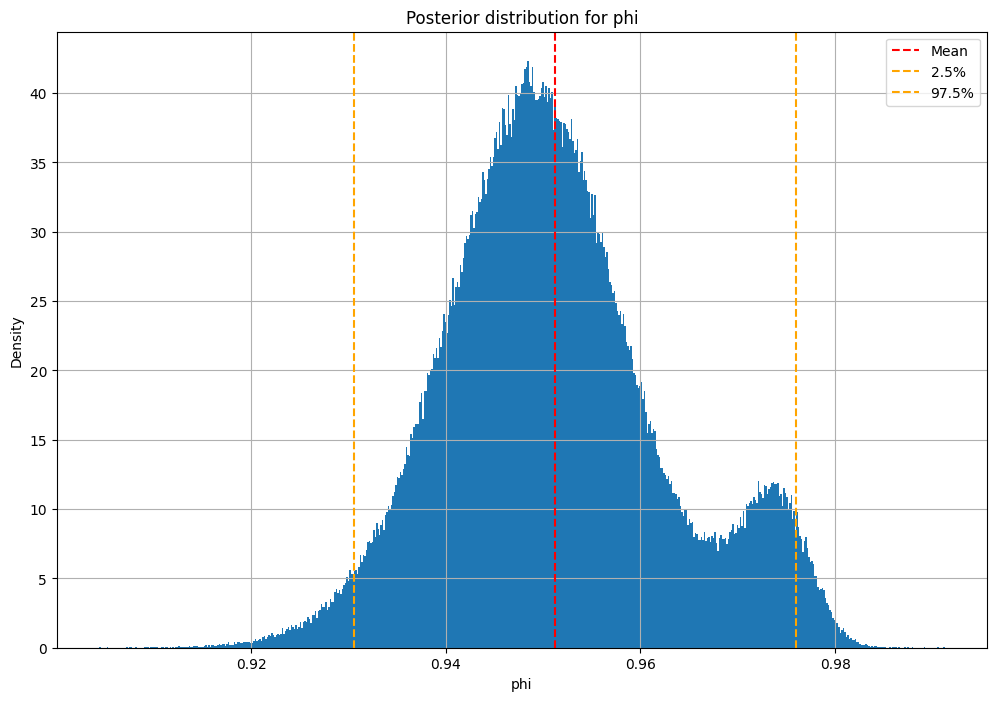

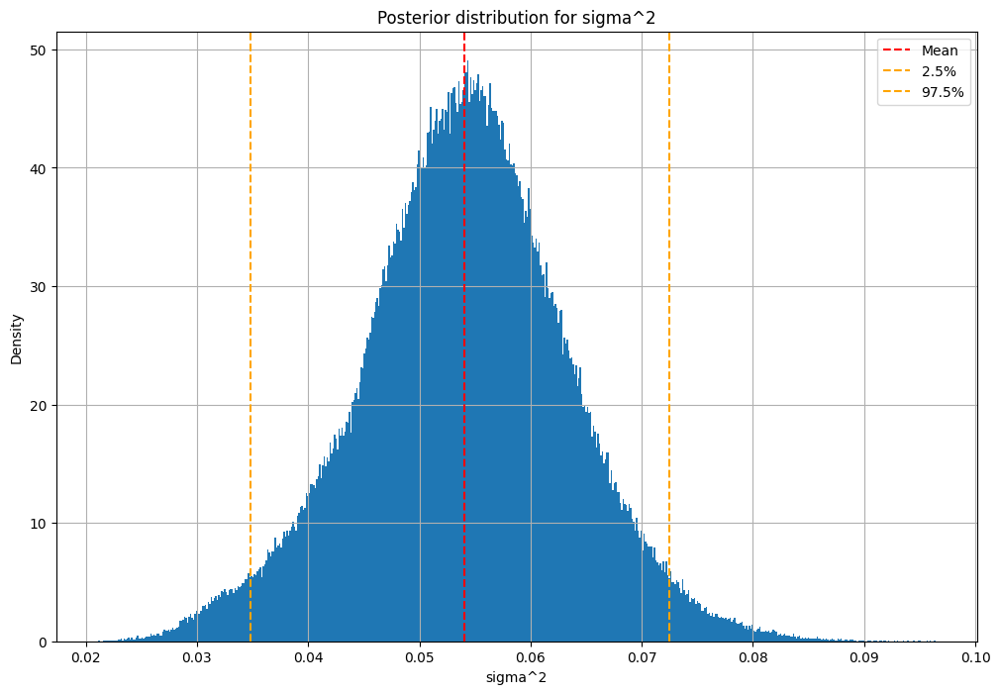

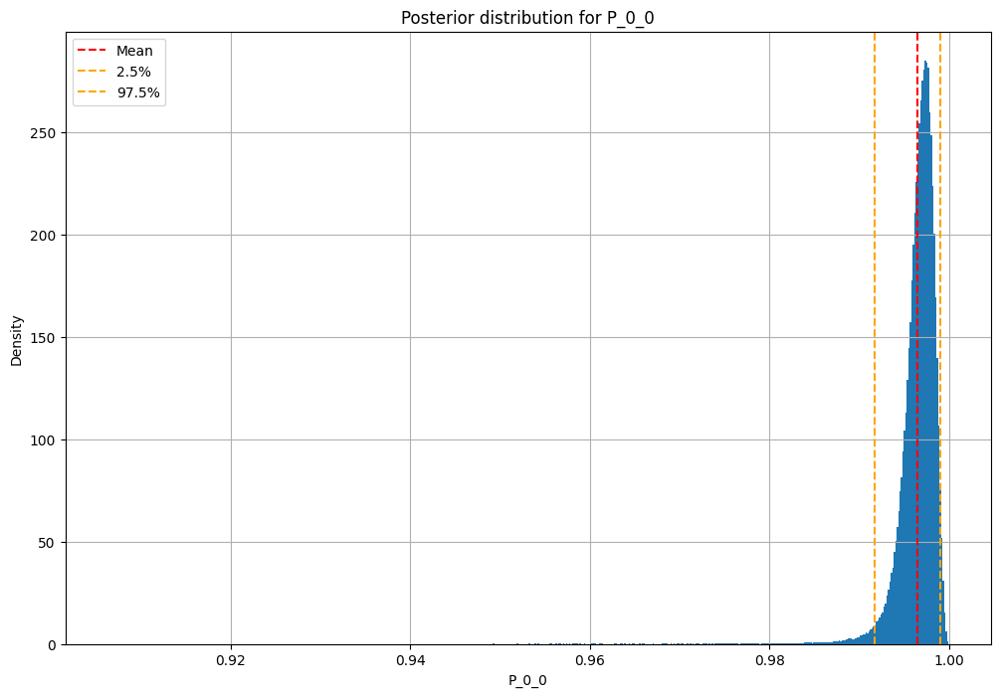

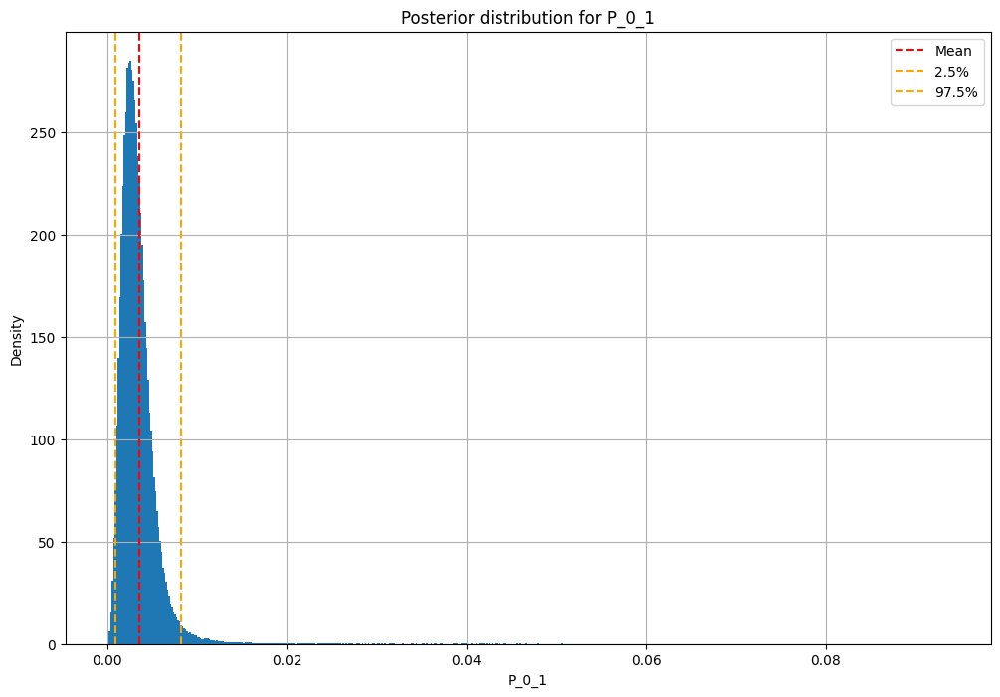

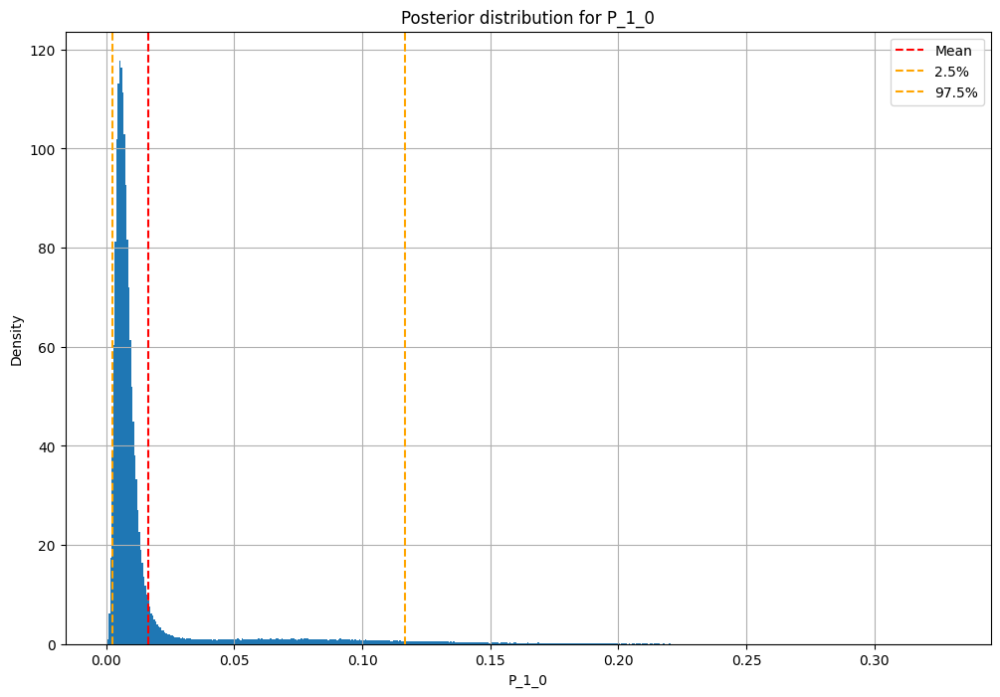

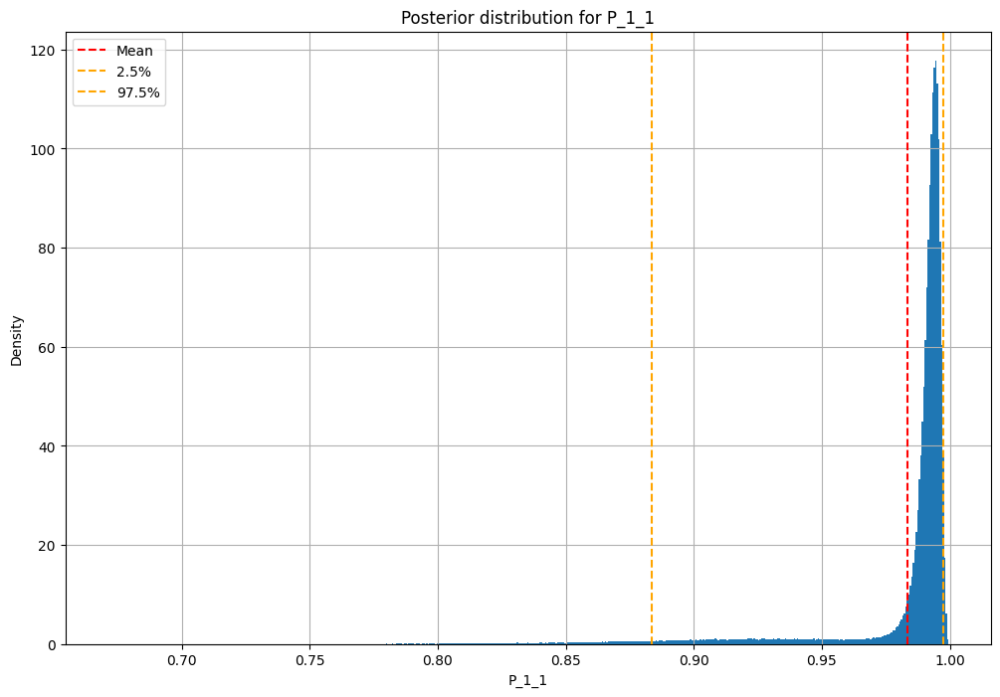

In [9]:
for param_idx in range(n_params):
    plt.figure(figsize=(12, 8))
    samples = []
    for i in range(n_chains):
        if i in collapsed_chains:
            continue  # Skip collapsed chains
        samples.extend(chains_data[i]["thetas"][:, param_idx])
    mean = np.mean(samples)
    lower, higher = np.percentile(samples, [2.5, 97.5])
    plt.hist(samples, bins=int(np.sqrt(len(samples))), density=True)
    plt.axvline(mean, color='red', linestyle='--', label='Mean')
    plt.axvline(lower, color='orange', linestyle='--', label='2.5%')
    plt.axvline(higher, color='orange', linestyle='--', label='97.5%')
    plt.xlabel(parameter_names[param_idx])
    plt.ylabel("Density")
    plt.title(f"Posterior distribution for {parameter_names[param_idx]}")
    plt.grid()
    plt.legend()
    plt.savefig(results_dir / f"{parameter_names[param_idx]}_hist.png")
    plt.show()

In [10]:
# Load the dates from real data
data = pd.read_csv(data_dir / "sp500" / "sp500.csv")
T = T_plus_1 - 1  # Exclude t=0 since it's the prior
# Keep only last T rows of data
data = data.tail(T)
dates = pd.to_datetime(data["Date"]).dt.date
dates = pd.to_datetime(dates).values

# Load the RV5 data
rv5_df = pd.read_csv(data_dir / "sp500" / "rv5_combined.csv")
rv5_values = rv5_df["RV5"].values
rv5_dates = pd.to_datetime(rv5_df["Date"]).dt.date
rv5_dates = pd.to_datetime(rv5_dates).values

In [12]:
h_values_all_chains = []
s_values_all_chains = []
for i in range(n_chains):
    if i in collapsed_chains:
        continue  # Skip collapsed chains
    h_values = chains_data[i]["trajectories"][:, :, 0]    # shape (M, T+1)
    h_values_all_chains.append(h_values)
    s_values = chains_data[i]["trajectories"][:, :, 1]   # shape (M, T+1)
    s_values_all_chains.append(s_values)

In [13]:
# Compute mean trajectory across all chains. We compute them manually to avoid memory issues with large datasets. 
C = len(s_values_all_chains)  # Number of chains
M = s_values_all_chains[0].shape[0]  # Number of samples per chain
print(f"Number of chains: {C}, Number of samples per chain: {M}")

mean_h_values = np.empty((T_plus_1,))
lower = np.empty(T_plus_1)
higher = np.empty(T_plus_1)

rng = np.random.default_rng(123)
subsampling_factor = 50  # Subsample factor to speed up computation
idx = rng.choice(M, size=M // subsampling_factor, replace=False)

for t in range(T_plus_1):
    if t % 500 == 0:
        print(f"Processing time point {t}/{T_plus_1}...")
        
    column = np.concatenate([chain[idx, t] for chain in h_values_all_chains])

    mean_h_values[t] = column.mean()
    lower[t], higher[t] = np.percentile(column, [2.5, 97.5])

Number of chains: 32, Number of samples per chain: 10000
Processing time point 0/6664...
Processing time point 500/6664...
Processing time point 1000/6664...
Processing time point 1500/6664...
Processing time point 2000/6664...
Processing time point 2500/6664...
Processing time point 3000/6664...
Processing time point 3500/6664...
Processing time point 4000/6664...
Processing time point 4500/6664...
Processing time point 5000/6664...
Processing time point 5500/6664...
Processing time point 6000/6664...
Processing time point 6500/6664...


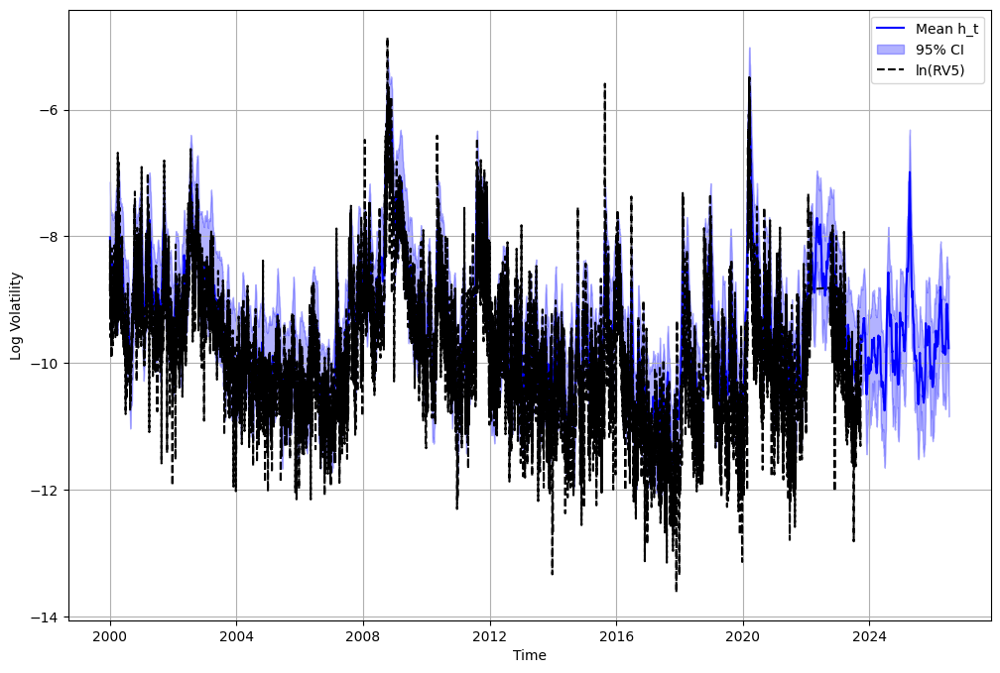

In [14]:
plt.figure(figsize=(12, 8))
plt.plot(dates, mean_h_values[1:], label="Mean h_t", color='blue')  
plt.fill_between(dates, lower[1:], higher[1:], color='blue', alpha=0.3, label="95% CI")
plt.plot(rv5_dates, np.log(rv5_values), label="ln(RV5)", color='black', linestyle='--')
plt.xlabel("Time")
plt.ylabel("Log Volatility")
plt.legend()
plt.grid()
plt.savefig(results_dir / "mean_h_trajectory.png")
plt.show()

In [ ]:
# Compute mean regime probabilities across all chains
mean_s_values = np.empty((T_plus_1,))

for t in range(T_plus_1):
    if t % 500 == 0:
        print(f"Processing time point {t}/{T_plus_1}...")

    column = np.concatenate([chain[idx, t] for chain in s_values_all_chains])

    mean_s_values[t] = np.mean(column, axis=0)

Processing time point 0/6664...
Processing time point 500/6664...
Processing time point 1000/6664...
Processing time point 1500/6664...
Processing time point 2000/6664...
Processing time point 2500/6664...
Processing time point 3000/6664...
Processing time point 3500/6664...
Processing time point 4000/6664...
Processing time point 4500/6664...
Processing time point 5000/6664...
Processing time point 5500/6664...
Processing time point 6000/6664...
Processing time point 6500/6664...


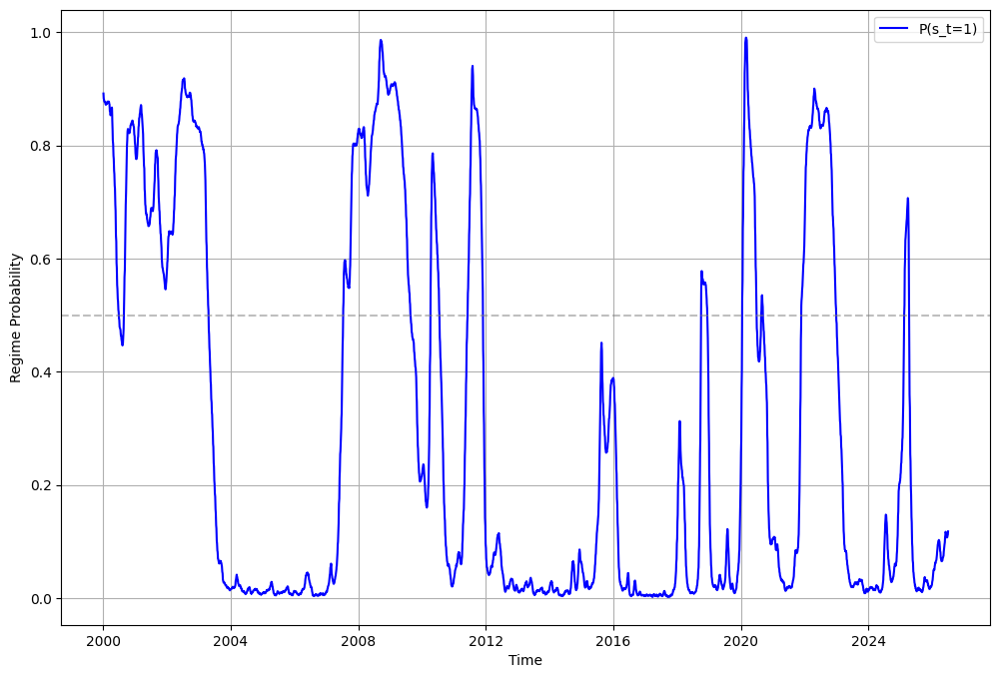

In [ ]:
plt.figure(figsize=(12, 8))
plt.plot(dates, mean_s_values[1:], label="P(s_t=1)", color='blue')
plt.axhline(0.5, color='grey', linestyle='--', alpha=0.5)
plt.xlabel("Time")
plt.ylabel("Regime Probability")
plt.legend()
plt.grid()
plt.savefig(results_dir / "mean_regime_probability.png")
plt.show()

### Bitcoin Data
First we look at BTC/USD data, since 1.1.2012. First plots are the traceplots of the parameters and the histograms of the posterior distributions. 

In [5]:
experiment_path = os.path.join(parent_dir, "experiments", "mssv_pg_btc")
name = "bitcoin"

output_dir = os.path.join(experiment_path, name, "output")
results_dir = os.path.join(experiment_path, name, "results")
data_dir = os.path.join(parent_dir, "data", "real")

# Convert to pathlib.Path objects for easier path manipulation
output_dir = Path(output_dir)
results_dir = Path(results_dir)
data_dir = Path(data_dir)

In [6]:
# Get number of chain files from output_dir
chain_files = list(output_dir.glob("chain_*.h5"))
n_chains = len(chain_files)
print(f"Found {n_chains} chain files.")
print(output_dir)

# Dictionary to store chain data
chains_data = {}

for i in range(n_chains):
    print(f"Processing chain {i+1}/{n_chains}...")
    with h5py.File(output_dir / f"chain_{i}.h5", "r") as h5f:
        initial_theta = h5f.attrs["initial_parameters"]
        thetas = h5f["thetas"][:]
        logmarliks = h5f["logmarliks"][:]
        trajectories = h5f["trajectories"][:]

        chains_data[i] = {
            "initial_theta": initial_theta,
            "thetas": thetas,
            "logmarliks": logmarliks,
            "trajectories": trajectories
        }

n_params = chains_data[0]["thetas"].shape[1]
T_plus_1 = chains_data[0]["trajectories"].shape[1]

parameter_names = generate_names(n_params)
print("Parameter names:", parameter_names)
print("Number of time points (T+1):", T_plus_1)

Found 32 chain files.
d:\School\Fakulteta\2. stopnja\2. letnik\Master\experiments\mssv_pg_btc\bitcoin\output
Processing chain 1/32...
Processing chain 2/32...
Processing chain 3/32...
Processing chain 4/32...
Processing chain 5/32...
Processing chain 6/32...
Processing chain 7/32...
Processing chain 8/32...
Processing chain 9/32...
Processing chain 10/32...
Processing chain 11/32...
Processing chain 12/32...
Processing chain 13/32...
Processing chain 14/32...
Processing chain 15/32...
Processing chain 16/32...
Processing chain 17/32...
Processing chain 18/32...
Processing chain 19/32...
Processing chain 20/32...
Processing chain 21/32...
Processing chain 22/32...
Processing chain 23/32...
Processing chain 24/32...
Processing chain 25/32...
Processing chain 26/32...
Processing chain 27/32...
Processing chain 28/32...
Processing chain 29/32...
Processing chain 30/32...
Processing chain 31/32...
Processing chain 32/32...
Parameter names: ['mu1', 'delta_2', 'phi', 'sigma^2', 'P_0_0', 'P_0_

In [7]:
K = int(-1+np.sqrt(n_params+1))
if K >= 2:
    # Identify the indices of the diagonal elements of the transition matrix P in the parameter vector
    P_diag_indices = [2 + K + i * (K + 1) for i in range(K)]
    print("Indices of diagonal elements of P:", P_diag_indices)

Indices of diagonal elements of P: [4, 7]


In [8]:
collapsed_chains = set()  # Use a set to avoid duplicates

for param_idx in range(n_params):
    for i in range(n_chains):
        if param_idx in P_diag_indices:
            if np.all(np.isclose(chains_data[i]["thetas"][:, param_idx], 1.0)):
                collapsed_chains.add(i)
            if np.all(np.isclose(chains_data[i]["thetas"][:, param_idx], 0.0)):
                collapsed_chains.add(i)

print(f"Chains that collapsed to 1 regime dynamics: {sorted(collapsed_chains)}")
print(f"Remaining chains: {sorted(set(range(n_chains)) - collapsed_chains)}")

Chains that collapsed to 1 regime dynamics: []
Remaining chains: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]


In [9]:
values = []
for param_idx in range(n_params):
    v = []
    for i in range(n_chains):
        if i in collapsed_chains:
            continue  # Skip processing for collapsed chains
        v.extend(chains_data[i]["thetas"][:, param_idx])
    values.append(v)

values = np.array(values)  # Convert to a NumPy array for easier manipulation
thetas = []
for t in values.T:
    theta = MSSVParams(
        mu1=t[0],
        delta=t[1:K],
        phi=t[K],
        eta2=t[K + 1],
        P=t[K + 2:].reshape((K, K))
    )
    thetas.append(theta.to_unconstrained())

thetas = np.array(thetas)
mean = np.mean(thetas, axis=0)
cov = np.cov(thetas, rowvar=False)

print("Mean of thetas:")
print(mean)
print("Covariance of thetas:")
print(cov)

Mean of thetas:
[-8.09311023  0.48506682  0.84590829 -0.37143746  4.98768539 -4.6802482 ]
Covariance of thetas:
[[ 0.01315292 -0.0009298   0.00277969 -0.00381891  0.01948243  0.0030144 ]
 [-0.0009298   0.00391199 -0.00141881  0.00147144 -0.00455     0.0058869 ]
 [ 0.00277969 -0.00141881  0.00661076 -0.00939344  0.00717818 -0.00537943]
 [-0.00381891  0.00147144 -0.00939344  0.01781025 -0.00619235  0.00471415]
 [ 0.01948243 -0.00455     0.00717818 -0.00619235  0.13487392 -0.04249447]
 [ 0.0030144   0.0058869  -0.00537943  0.00471415 -0.04249447  0.10784807]]


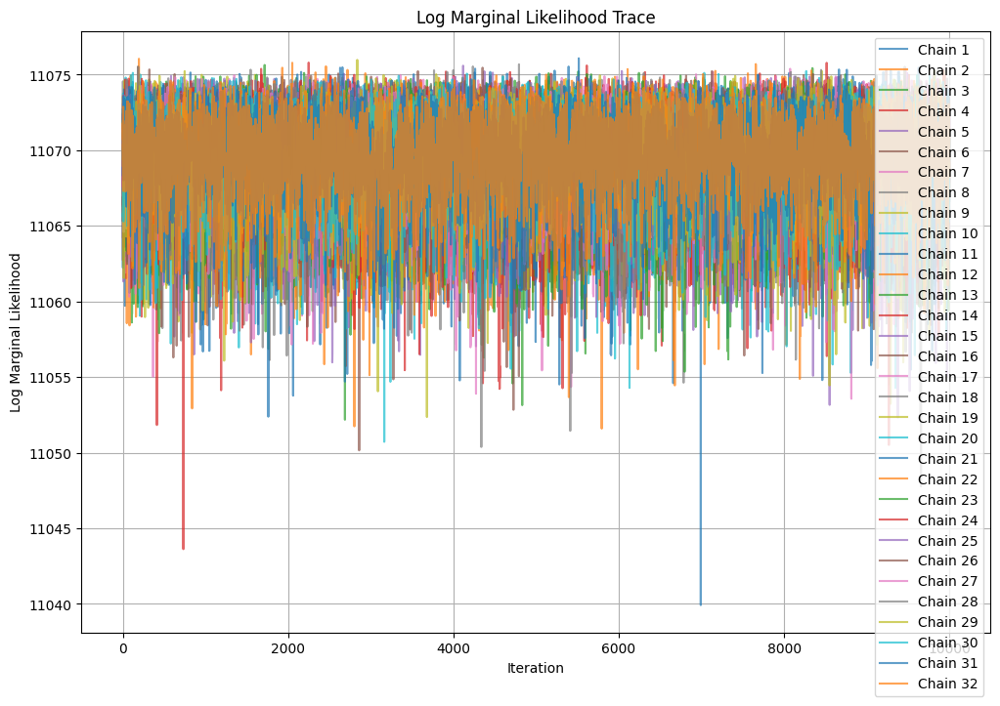

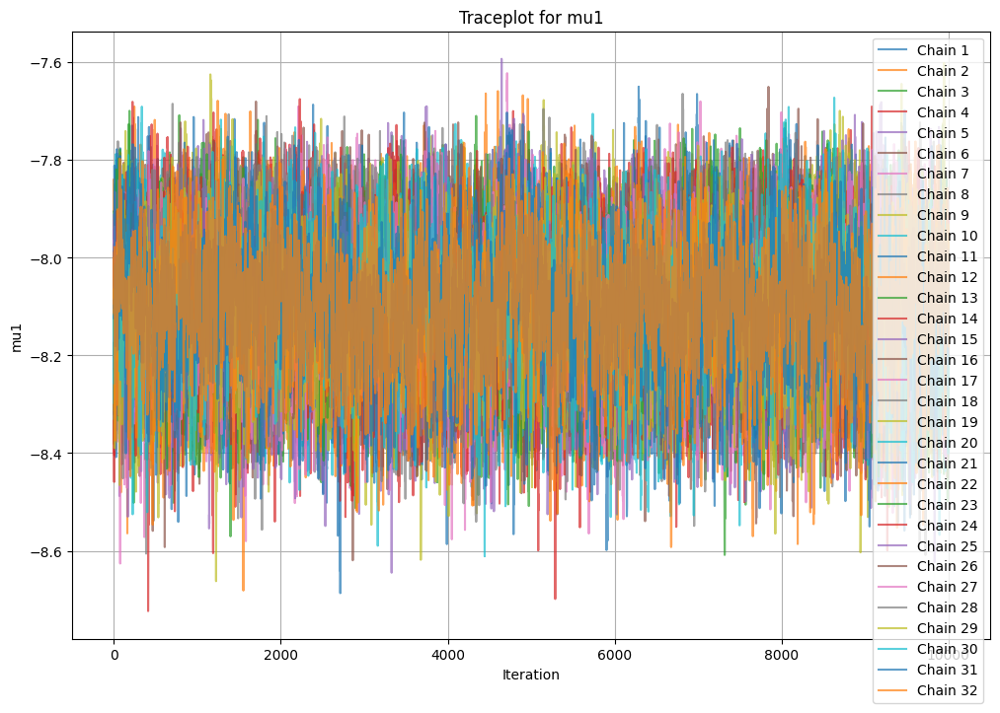

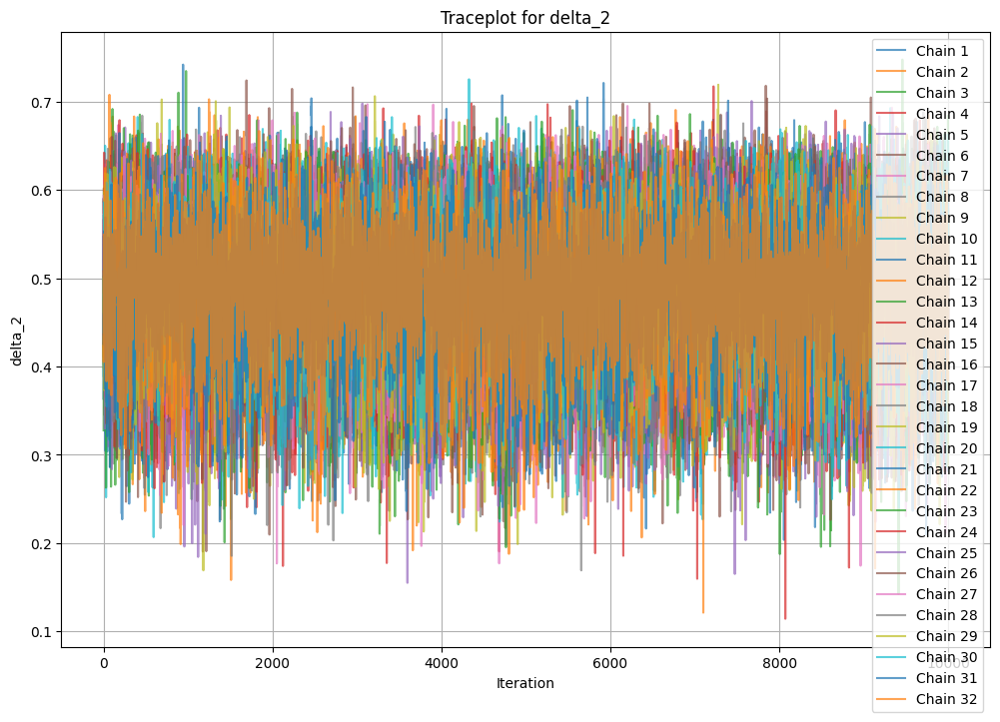

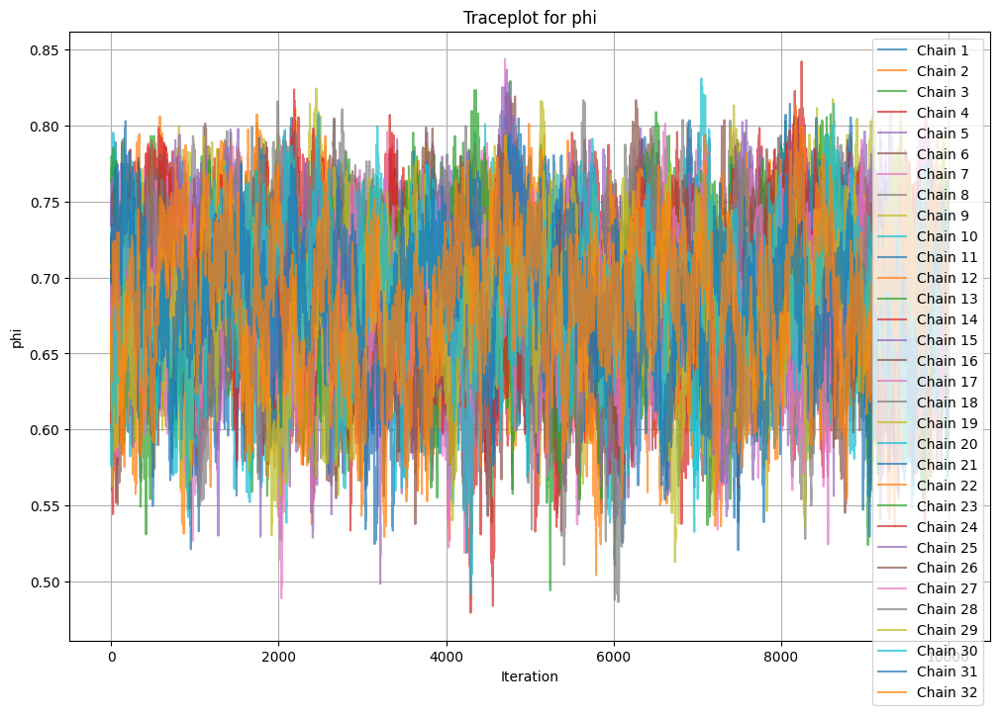

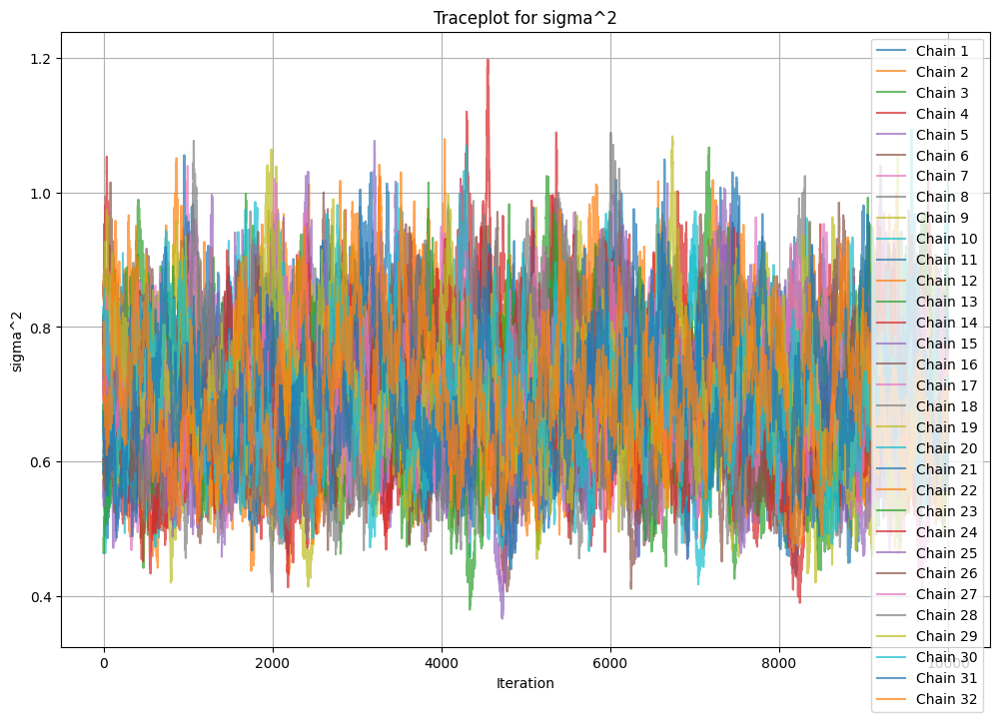

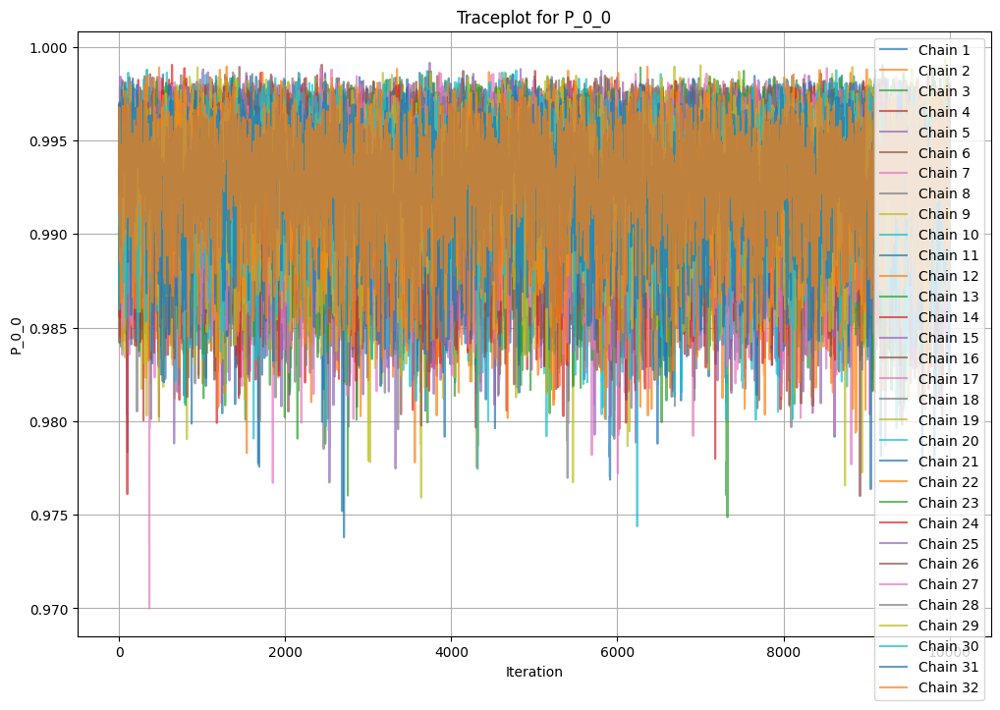

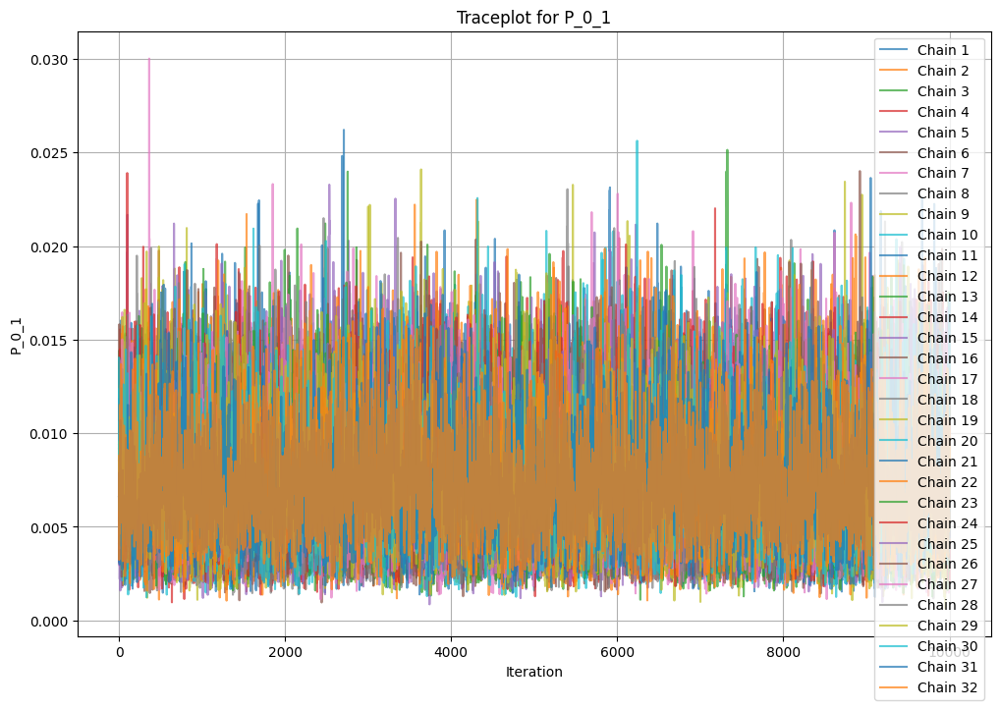

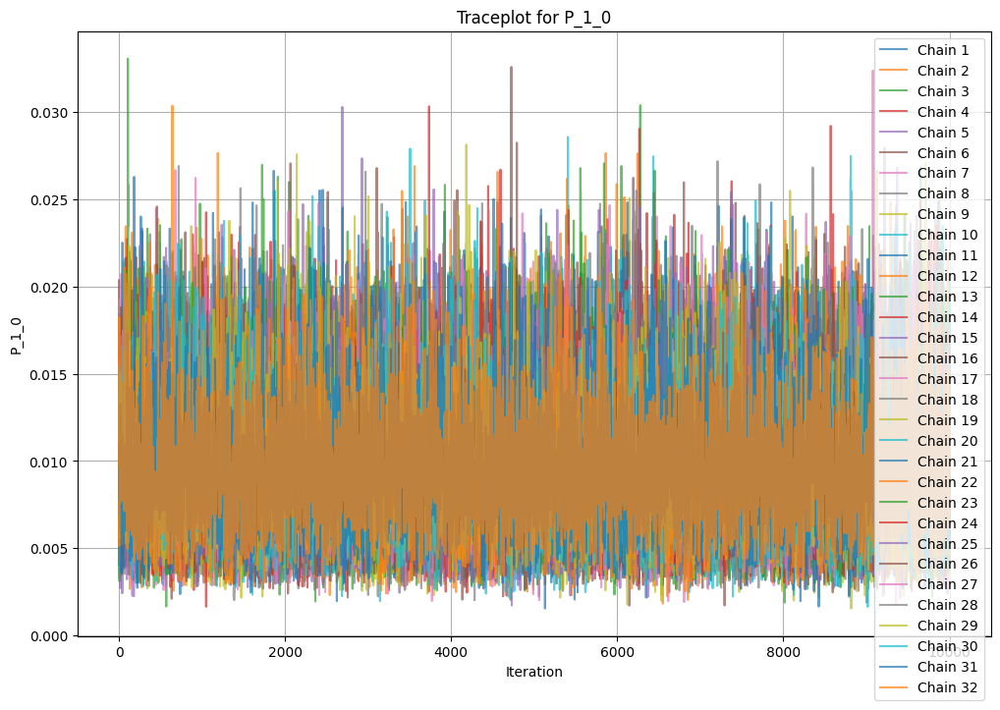

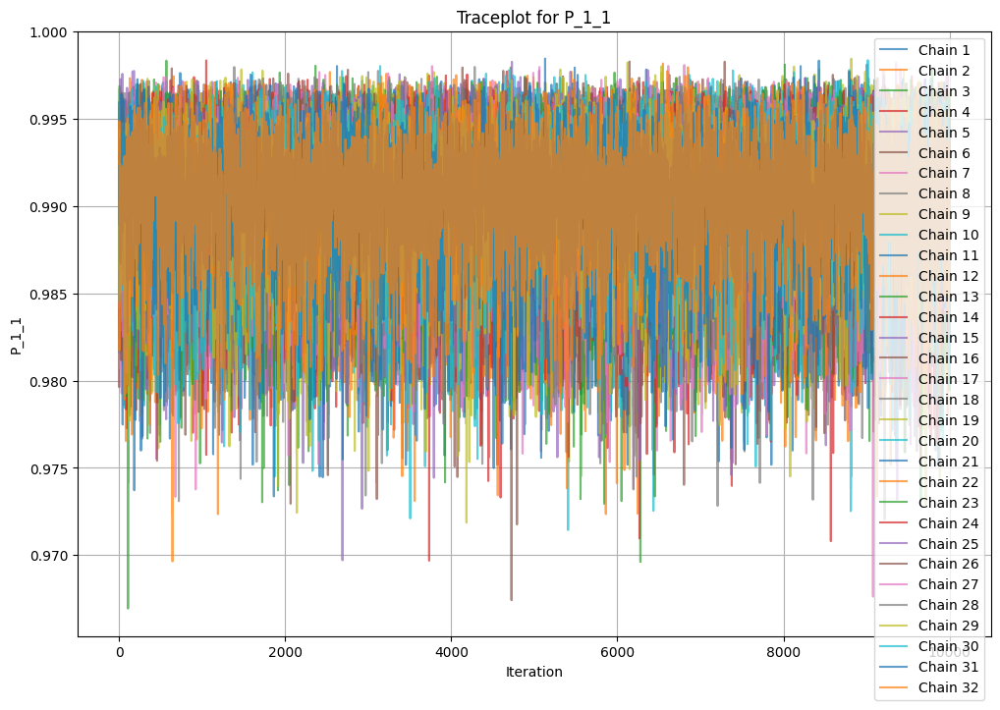

In [10]:
plt.figure(figsize=(12, 8))
for i in range(n_chains):
    if i in collapsed_chains:
        continue  # Skip plotting for collapsed chains
    plt.plot(chains_data[i]["logmarliks"], label=f"Chain {i+1}", alpha=0.7)
plt.xlabel("Iteration")
plt.ylabel("Log Marginal Likelihood")
plt.title("Log Marginal Likelihood Trace")
plt.legend()
plt.grid()
plt.savefig(results_dir / "logmarlik_trace.png")
plt.show()

for param_idx in range(n_params):
    plt.figure(figsize=(12, 8))
    for i in range(n_chains):
        if i in collapsed_chains:
            continue  # Skip plotting for collapsed chains
        plt.plot(chains_data[i]["thetas"][:, param_idx], label=f"Chain {i+1}", alpha=0.7)
    plt.xlabel("Iteration")
    plt.ylabel(parameter_names[param_idx])
    plt.title(f"Traceplot for {parameter_names[param_idx]}")
    plt.legend()
    plt.grid()
    plt.savefig(results_dir / f"{parameter_names[param_idx]}_trace.png")
    plt.show()

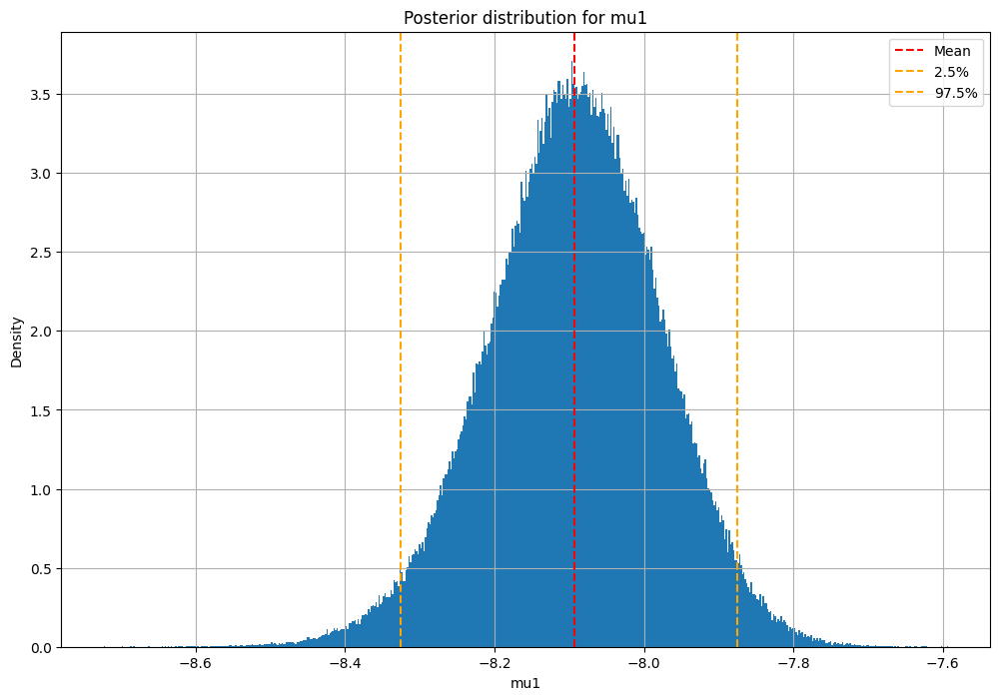

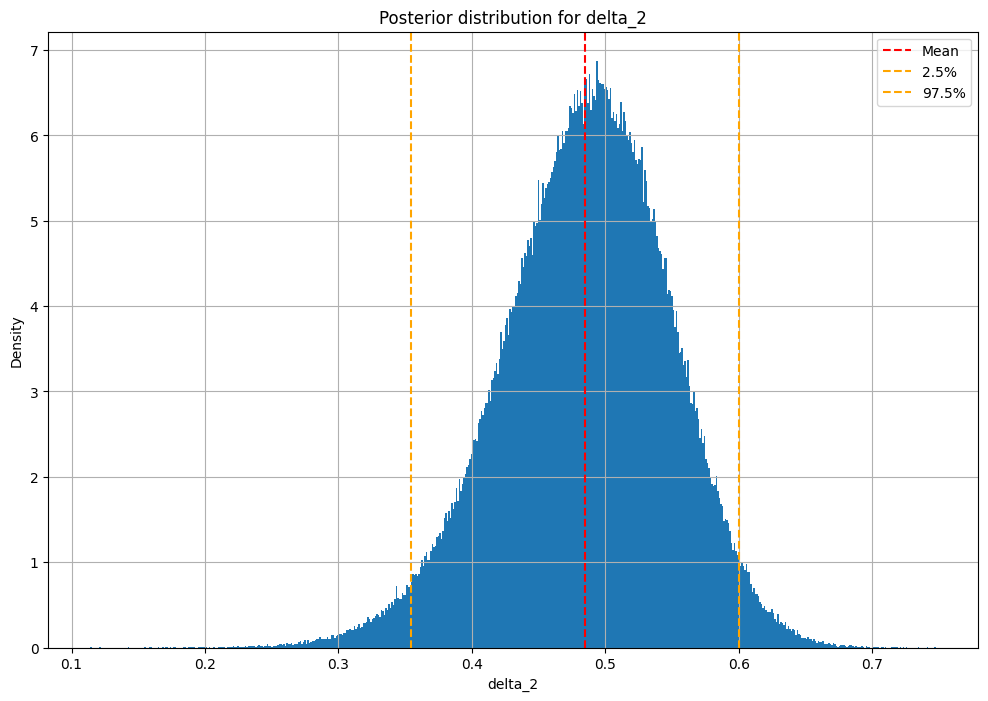

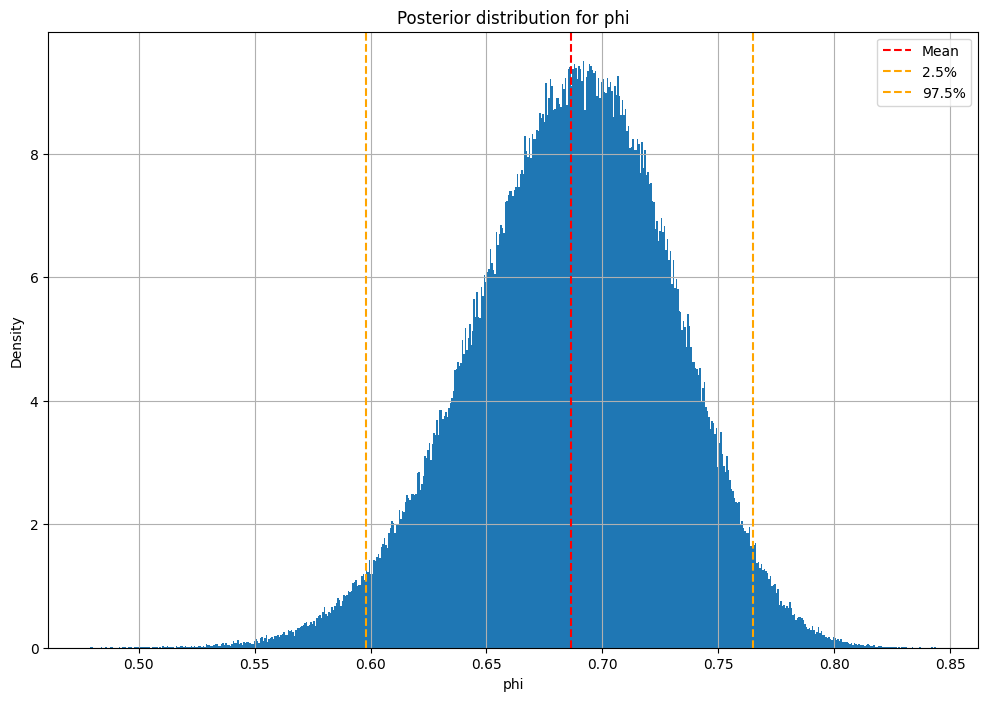

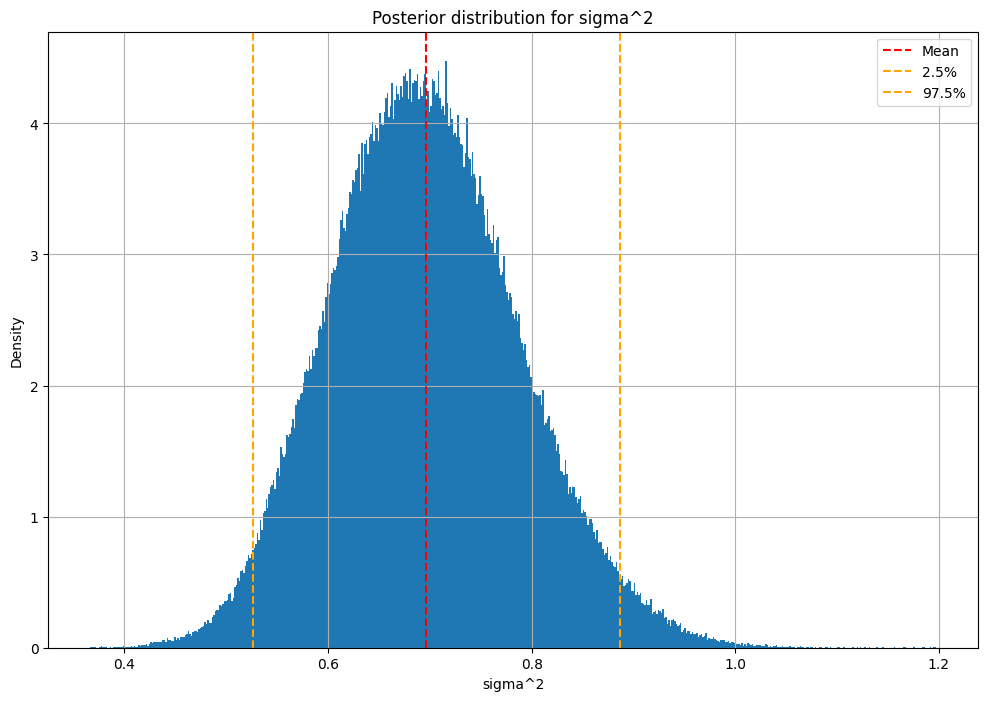

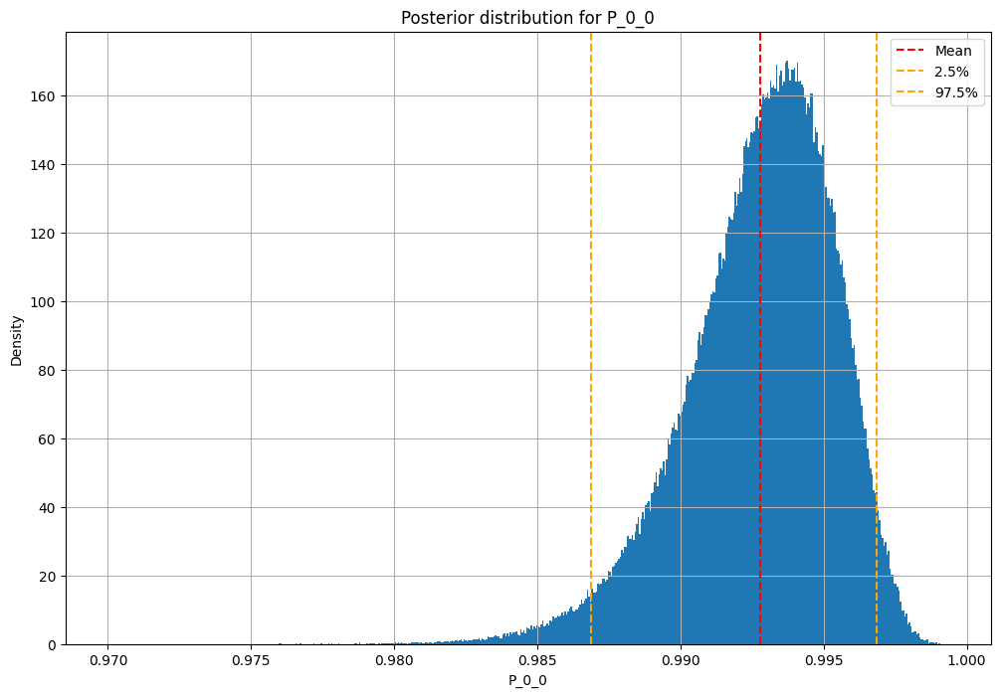

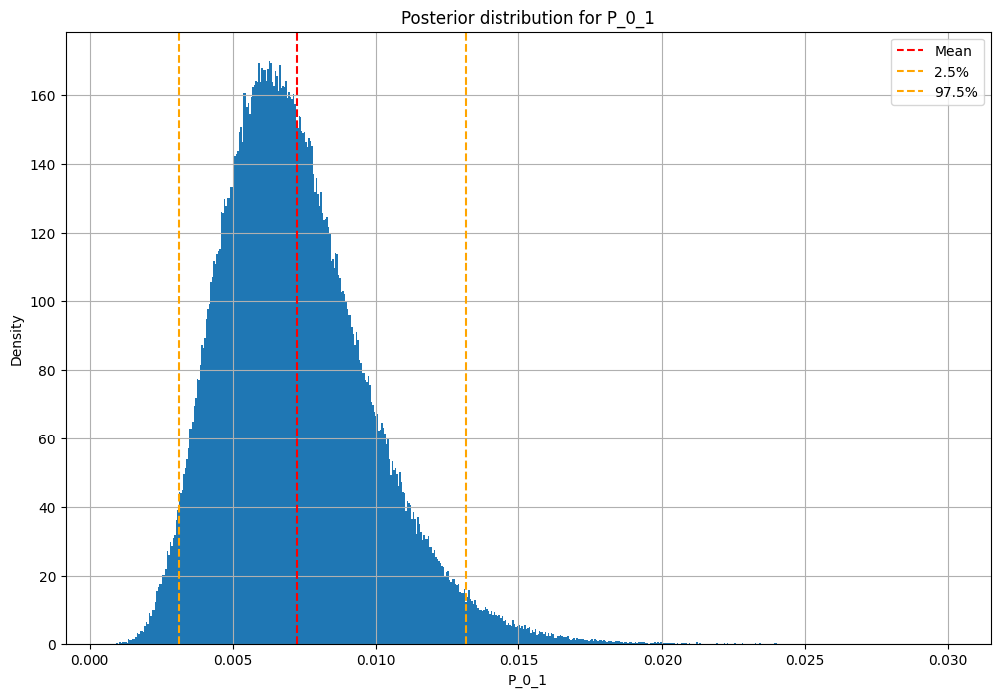

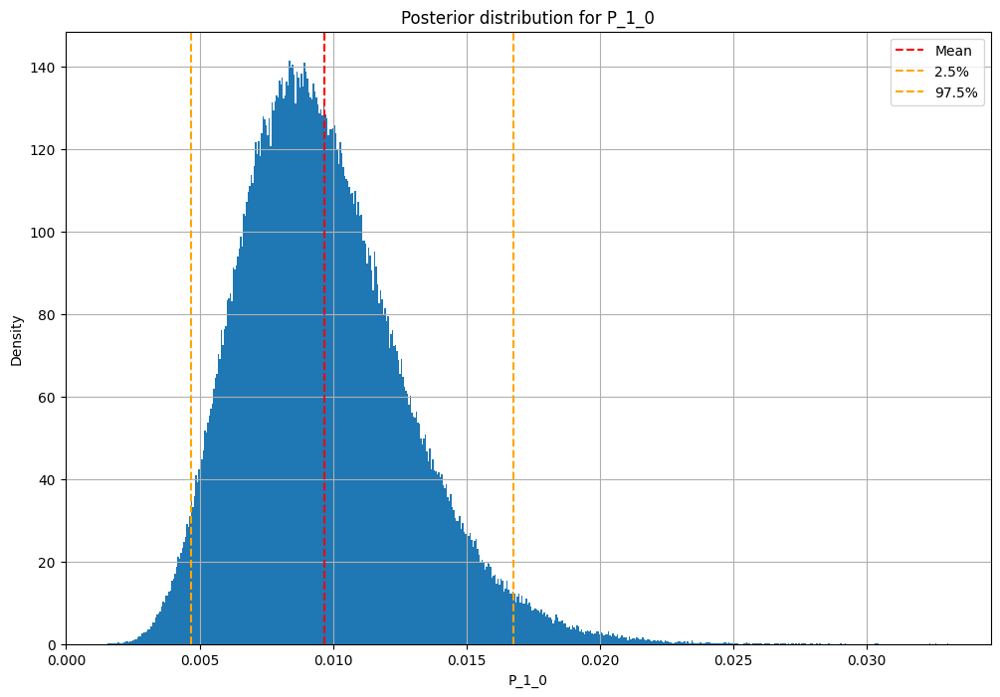

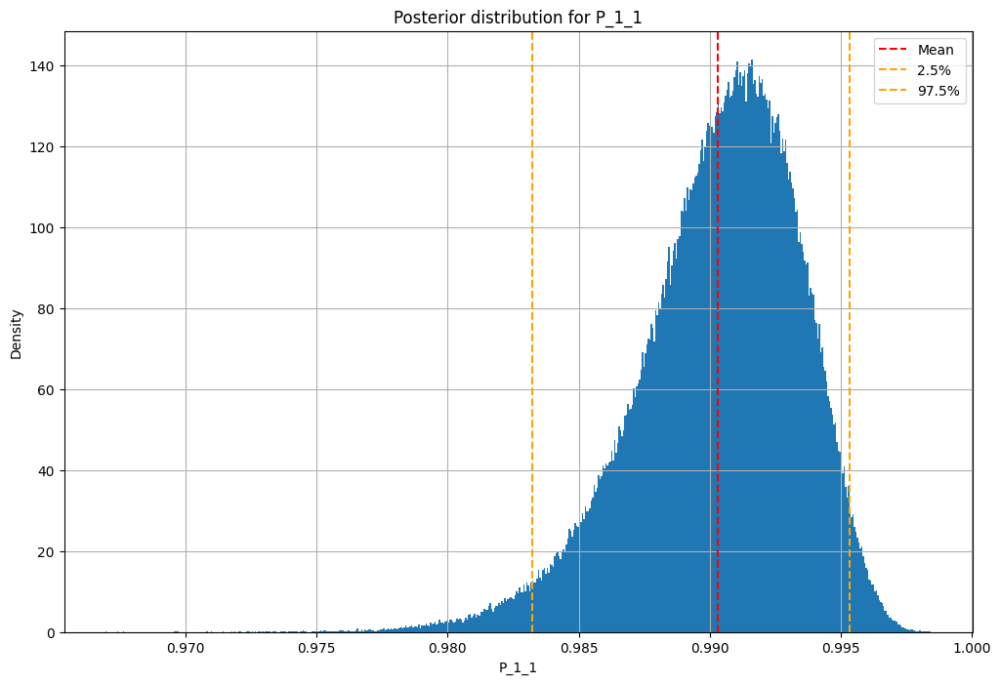

In [11]:
for param_idx in range(n_params):
    plt.figure(figsize=(12, 8))
    samples = []
    for i in range(n_chains):
        if i in collapsed_chains:
            continue  # Skip collapsed chains
        samples.extend(chains_data[i]["thetas"][:, param_idx])
    mean = np.mean(samples)
    lower, higher = np.percentile(samples, [2.5, 97.5])
    plt.hist(samples, bins=int(np.sqrt(len(samples))), density=True)
    plt.axvline(mean, color='red', linestyle='--', label='Mean')
    plt.axvline(lower, color='orange', linestyle='--', label='2.5%')
    plt.axvline(higher, color='orange', linestyle='--', label='97.5%')
    plt.xlabel(parameter_names[param_idx])
    plt.ylabel("Density")
    plt.title(f"Posterior distribution for {parameter_names[param_idx]}")
    plt.grid()
    plt.legend()
    plt.savefig(results_dir / f"{parameter_names[param_idx]}_hist.png")
    plt.show()

In [12]:
# Load the RV5 data
rv5_df = pd.read_csv(data_dir / "bitcoin" / "rv5_btc.csv")
rv5_values = rv5_df["RV5"].values
rv5_dates = pd.to_datetime(rv5_df["Date"]).dt.date
rv5_dates = pd.to_datetime(rv5_dates).values

In [ ]:
h_values_all_chains = []
s_values_all_chains = []
for i in range(n_chains):
    if i in collapsed_chains:
        continue  # Skip collapsed chains
    h_values = chains_data[i]["trajectories"][:, :, 0]    # shape (M, T+1)
    h_values_all_chains.append(h_values)
    # Construct back the one-hot encoded regime indicators
    s_values = chains_data[i]["trajectories"][:, :, 1]   # shape (M, T+1)
    s_values_all_chains.append(s_values)

In [15]:
# Compute mean trajectory across all chains
C = len(s_values_all_chains)  # Number of chains
M = s_values_all_chains[0].shape[0]  # Number of samples per chain
print(f"Number of chains: {C}, Number of samples per chain: {M}")

mean_h_values = np.empty((T_plus_1,))
lower = np.empty(T_plus_1)
higher = np.empty(T_plus_1)

rng = np.random.default_rng(123)
subsampling_factor = 50  # Subsample factor to speed up computation
idx = rng.choice(M, size=M // subsampling_factor, replace=False)

for t in range(T_plus_1):
    if t % 500 == 0:
        print(f"Processing time point {t}/{T_plus_1}...")
        
    column = np.concatenate([chain[idx, t] for chain in h_values_all_chains])

    mean_h_values[t] = np.mean(column)
    lower[t], higher[t] = np.percentile(column, [2.5, 97.5])


Number of chains: 32, Number of samples per chain: 10000
Processing time point 0/5311...
Processing time point 500/5311...
Processing time point 1000/5311...
Processing time point 1500/5311...
Processing time point 2000/5311...
Processing time point 2500/5311...
Processing time point 3000/5311...
Processing time point 3500/5311...
Processing time point 4000/5311...
Processing time point 4500/5311...
Processing time point 5000/5311...


C:\Users\vitol\AppData\Local\Temp\ipykernel_10296\1478014008.py:4: RuntimeWarning: divide by zero encountered in log
  plt.plot(rv5_dates, np.log(rv5_values), label="ln(RV5)", color='black', linestyle='--')


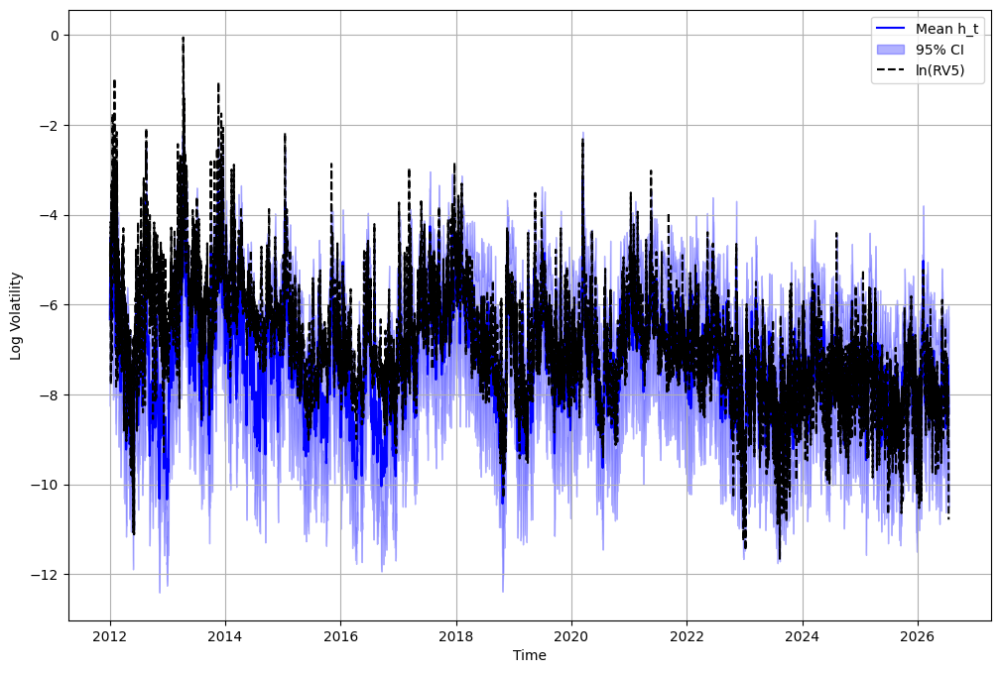

In [16]:
plt.figure(figsize=(12, 8))
plt.plot(rv5_dates, mean_h_values[1:], label="Mean h_t", color='blue')  
plt.fill_between(rv5_dates, lower[1:], higher[1:], color='blue', alpha=0.3, label="95% CI")
plt.plot(rv5_dates, np.log(rv5_values), label="ln(RV5)", color='black', linestyle='--')
plt.xlabel("Time")
plt.ylabel("Log Volatility")
plt.legend()
plt.grid()
plt.savefig(results_dir / "mean_h_trajectory.png")
plt.show()

In [17]:
# Compute mean regime probabilities across all chains
mean_s_values = np.empty((T_plus_1, K))

for t in range(T_plus_1):
    if t % 500 == 0:
        print(f"Processing time point {t}/{T_plus_1}...")
    
    column = np.concatenate([chain[idx, t] for chain in s_values_all_chains])

    mean_s_values[t] = np.mean(column, axis=0)

Processing time point 0/5311...
Processing time point 500/5311...
Processing time point 1000/5311...
Processing time point 1500/5311...
Processing time point 2000/5311...
Processing time point 2500/5311...
Processing time point 3000/5311...
Processing time point 3500/5311...
Processing time point 4000/5311...
Processing time point 4500/5311...
Processing time point 5000/5311...


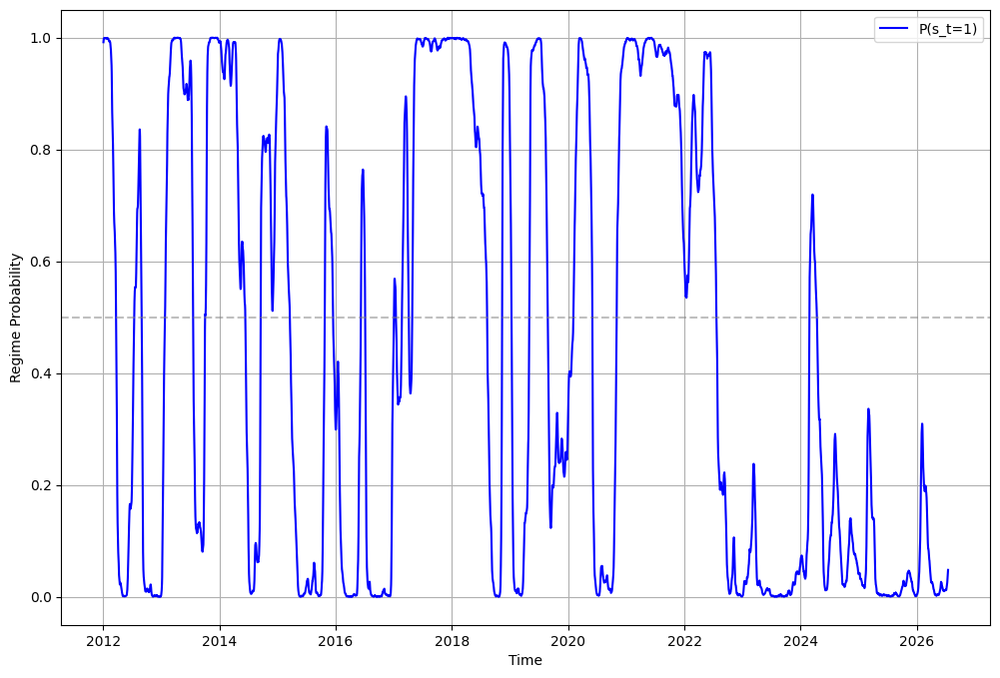

In [18]:
plt.figure(figsize=(12, 8))
plt.plot(rv5_dates, mean_s_values[1:, 1], label="P(s_t=1)", color='blue')
plt.axhline(0.5, color='grey', linestyle='--', alpha=0.5)
plt.xlabel("Time")
plt.ylabel("Regime Probability")
plt.legend()
plt.grid()
plt.savefig(results_dir / "mean_regime_probability.png")
plt.show()